### Laboratorium 4, część 1: Detekcja obiektów metodami klasycznymi

#### _Fabuła_
_Aby nauczyć głęboki model do segmentacji_ amodalnej _(tj. odpornej na okluzje między obiektami) konieczne jest skonstruowanie odpowiednio anotowanego zbioru uczącego.
Pozyskanie takich danych w drodze manualnej anotacji jest zbyt kosztowne, dlatego obieramy podejście oparte o generowanie danych syntetycznych.
Dane generowane będą na podstawie zbioru_ modalnego, _tj. zawierającego wyłącznie nieprzysłonięte obiekty.
Obiekty te należy najpierw wysegmentować ze specjalnie przygotowanych obrazów źródłowych, a następnie przeanalizować ich kształty -- ten właśnie krok będzie Twoim zadaniem._

#### Zadania

Twoim celem jest wykonanie detekcji i segmentacji _obiektów zainteresowania_ z podanych obrazów źródłowych.

W **pierwszej kolejności** przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający kolekcję obiektów opisanych (1) prostokątem otaczającym (_bounding box_) - na potrzeby detekcji, oraz (2) maską binarną **lub** konturem (tj. zbiorem koordynat punktów brzegowych).
Potok przetwarzania powinien obejmować binaryzację obrazu kolorowego (znanymi Ci już metodami), detekcję komponentów spójności ([`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0)), oraz analizę blobów binarnych (obiektów).
Wykryte obiekty należy przefiltrować tak, aby pozostawić wyłącznie _obiekty zainteresowania_, tj. pojedyncze larwy.
Należy więc usunąć:
* drobne obiekty niebędące larwami,
* instancje złączone,
* wszelkie inne zakłócenia.

Zaimplementuj również funkcję pozwalającą na zaprezentowanie wyników detekcji w formie rysowania prostokątów odpowiadających instancjom oraz segmentacji w formie zaznaczania pikseli należących do instancji (może być w jednej funkcji z opcją wyboru).

**Następnie** opracujesz moduł przetwarzania poszczególnych instancji na poziomie masek binarnych lub konturów.
Moduł ten ma przyjmować pojedynczą instancję i wyznaczać dla niej podstawowe informacje, takie jak:
* długość (skorzystaj z [`skimage.morphology.skeletonize`](https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.skeletonize)) - relatywnie łatwa do _estymacji_, ale dość trudna do precyzyjnego _pomiaru_,
* grubość - może stanowić wyzwanie,
* klasyfikację kształtu (I-kształtne, S-kształtne, C-kształtne) -- potencjalnie trudne zadanie,
* ...

Nie musisz implementować ich wszystkich: na maksymalną ocenę wystarczą dwie miary zrobione _nieźle_ lub jedna opracowana _solidnie_.

#### Oczekiwane rezultaty
1. Zaprojektowanie potoku przetwarzania do detekcji i segmentacji - skonstruuj go najlepiej jako pojedynczą funkcję, ale pozostaw ślad z dokonywanych po drodze eksperymentów, tak aby możliwe było przeanalizowanie przebiegu operacji krok po kroku.
2. Zadbaj o możliwość przetworzenia tylko wybranego RoI z obrazu, aby można było przyjrzeć się "z bliska" wybranym rejonom (np. trudniejszym) -- rekomenduję zacząć pracę od wybrania mniejszego, wygodniejszego w przetwarzaniu rejonu.
3. Działanie modułu analizy zademonstruj na kilku wybranych przykładach, także umożliwiając podgląd operacji krok po kroku.
4. Debugging - jeśli na którymkolwiek etapie pojawią się problemy, których nie potrafisz rozwiązać, postaraj się przynajmniej przeanalizować, co je powoduje.

#### Literatura
1. [`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0), [OpenCV Structural Analysis and Shape Descriptors](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html), [OpenCV Drawing Functions](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html)
2. Publikacja, której częścią był potok przetwarzania podobny do tego, który zaimplementujesz: https://ieeexplore.ieee.org/document/10924163

In [1]:
from collections import Counter
from typing import List

import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage.morphology as skm
from skimage.graph import MCP_Geometric, pixel_graph
from skimage.measure import find_contours
from skimage.segmentation import expand_labels
from scipy.ndimage import gaussian_filter1d, map_coordinates
from IPython.display import Markdown, display

In [2]:
# staraj się projektować potok przetwarzania na jednym obrazie, a następnie przetestować go na drugim
calib = cv2.imread('Lab4_dane/proc_20221213112112426_image0.jpg')
test = cv2.imread('Lab4_dane/proc_20221213112219030_image0.jpg')
assert calib is not None and test is not None, 'Nie wczytano obrazów - sprawdź ścieżkę'

# Pracuję tylko na dnie pudełka: stały prostokąt (wiersze, kolumny), opis niżej. Pełne obrazy zostają w *_full.
FLOOR = (slice(255, 2730), slice(132, 3970))   # dno pudełka (275:2710, 152:3950) poszerzone o 20 px z każdej strony
calib_full, test_full = calib, test
calib, test = calib_full[FLOOR].copy(), test_full[FLOOR].copy()

### Obszar roboczy: dno pudełka

Obraz tnę od razu po wczytaniu do dna pudełka, czyli stałego prostokąta `FLOOR`. Cały dalszy potok, łącznie z wyborem RoI, pracuje już tylko na tym wycinku. Kamera wisi na stałej wysokości, a pudełko stoi w tym samym miejscu: między `calib` a `test` przesuwa się o ok. 5 px. 

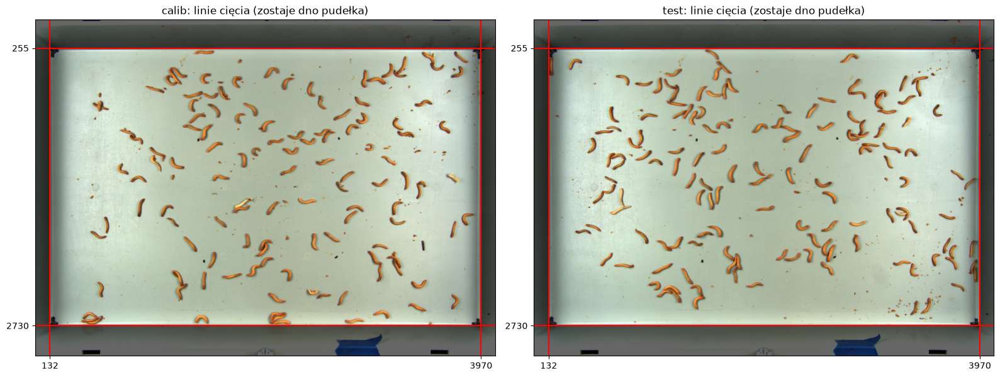

In [3]:
# Linie cięcia na obu obrazach wejściowych: zostaje dno pudełka (prostokąt FLOOR), odcięta część jest przyciemniona
ys, xs = FLOOR
f, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, img, name in zip(axes, (calib_full, test_full), ('calib', 'test')):
    vis = np.ascontiguousarray(img[..., ::-1])
    shown = cv2.convertScaleAbs(vis, alpha=0.4)
    shown[FLOOR] = vis[FLOOR]
    ax.imshow(shown)
    for y in (ys.start, ys.stop):
        ax.axhline(y, color='red', lw=1.5)
    for x in (xs.start, xs.stop):
        ax.axvline(x, color='red', lw=1.5)
    ax.set_xticks([xs.start, xs.stop])
    ax.set_yticks([ys.start, ys.stop])
    ax.set_title(f'{name}: linie cięcia (zostaje dno pudełka)')
plt.tight_layout()

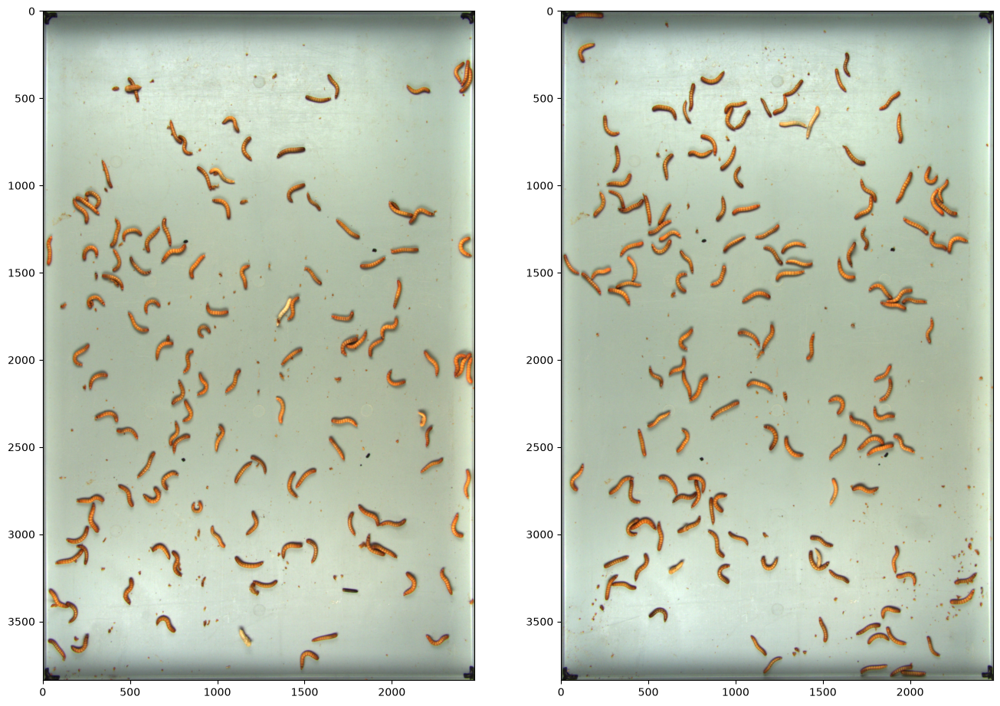

In [4]:
# Obrazy po cięciu: na nich pracuje cały potok (także RoI)
f, (a1, a2) = plt.subplots(1,2,figsize=(16,12))
a1.imshow(calib[...,::-1].transpose((1,0,2)))
a2.imshow(test[...,::-1].transpose((1,0,2)))

### Potok detekcji

Potok odwzorowuje segmentację z artykułu (sekcja III-B2c) i dodaje krok 6. `detect_objects` wywołuje kolejno funkcje sześciu kroków, a ich domyślne argumenty to parametry końcowe:

| krok | funkcja | artykuł | parametry końcowe |
|---|---|---|---|
| 1 | `rough_mask` | globalny próg na S | `S_THR` = 104 (Otsu na `calib`) |
| 2 | `find_candidates` | filtr pola, ROI | `min_area` = 1500 px, `margin` = 10 px |
| 3 | `segment_candidate` | lokalny próg z histogramu ROI | `K_GROW` = elipsa 7×7 |
| 4 | `segment_candidate` → `refine_edges` | adaptacyjna erozja (kanał B) | `refine_alpha` = 0.25 (`delta` = `alpha` × kontrast B w ROI), `refine_iters` = 4 |
| 5 | `blob_features`, `filter_candidates` | ręczne usunięcie zlepków | `max_extra` = 3 px; `k_len`, `k_width`, `k_area` = 1.35, 1.25, 1.6 |
| 6 | `split_candidates` → `split_candidate`, `clump_parts` | brak (rozszerzenie) | progi na S co `thr_step` = 10 do 200, `open_k` = 5, `grow` = 6 px, `min_part` = 500 px, `k_min` = 0.7, `min_cover` = 0.94, `k_neck` = 0.5 |

Krok 6 nie ma odpowiednika w artykule: kandydatów odrzuconych w kroku 5 rozdziela na larwy albo usuwa z larwy przyklejoną wypustkę (okruch, wylinkę). `detect_objects(..., split=False)` zwraca wynik samych kroków 1–5.

Parametry dobierałem iteracyjnie, notatnik pokazuje stan końcowy. Każdy eksperyment zmienia jeden parametr, a pozostałe mają wartości końcowe. Do podglądu służą `show_candidate_steps` (kroki 1–5 dla jednego kandydata), `show_splits` (krok 6) i `display_objects` (prostokąty, maski, odrzuceni kandydaci z powodem).

**Kolory na wyniku końcowym** są takie same w każdej wizualizacji: zielony kontur = obiekt przyjęty, czerwony kontur = obiekt odrzucony. Szkielety, ścieżki, znaczniki i wypełnienia mają inne kolory.

#### Funkcje pomocnicze

In [5]:
def skeleton_longest_path(skel: np.ndarray):
    """Najdłuższa ścieżka w szkielecie: dwa przebiegi „najdalszego punktu” (dokładne dla drzew).
    Odległości po pikselach szkieletu liczy `skimage.graph.MCP_Geometric` (8-sąsiedztwo: krok prosty 1, ukośny √2).
    Zwraca (długość w px, punkty ścieżki jako tablicę (N, 2) [y, x])."""
    if not skel.any():
        return 0.0, np.empty((0, 2), int)
    cost = np.where(skel, 1.0, np.inf)  # poza szkieletem nie da się przejść

    def farthest(start):
        mcp = MCP_Geometric(cost, fully_connected=True)
        dist, _ = mcp.find_costs([start])
        dist[~np.isfinite(dist)] = -1
        end = np.unravel_index(np.argmax(dist), dist.shape)
        return end, float(dist[end]), mcp

    a, _, _ = farthest(tuple(np.argwhere(skel)[0]))  # od dowolnego punktu do najdalszego końca a
    b, length, mcp = farthest(a)                      # od a do najdalszego końca b: ścieżka a-b
    return length, np.array(mcp.traceback(b))


def skeleton_total_length(skel: np.ndarray) -> float:
    """Suma długości wszystkich gałęzi szkieletu. `skimage.graph.pixel_graph` łączy sąsiednie piksele szkieletu
    (8-sąsiedztwo) krawędziami o wadze równej odległości środków (1 lub √2). Macierz jest symetryczna,
    więc każda krawędź jest liczona dwa razy."""
    graph, _ = pixel_graph(skel, mask=skel, connectivity=2)
    return float(graph.sum() / 2)


def b_contrast(mask: np.ndarray, blue: np.ndarray) -> float:
    """Kontrast tło - obiekt na kanale B w ROI: mediana B tła minus średnia B obiektu.
    Tło = piksele ROI odległe od maski o co najmniej 4 px (bez pikseli mieszanych). Wpadają do niego też cień
    i fragmenty sąsiednich larw, ale mediana jest na nie odporna."""
    far = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))) == 0
    return float(np.median(blue[far])) - float(blue[mask > 0].mean())


def refine_edges(mask: np.ndarray, blue: np.ndarray, alpha: float = 0.25, iters: int = 4) -> np.ndarray:
    """Adaptacyjna erozja brzegu (wg artykułu): piksel brzegowy jest usuwany, jeśli średnia kanału B
    w jego otoczeniu 3x3 jest jaśniejsza od średniej B całego obiektu o więcej niż delta.
    delta = alpha x kontrast tło - obiekt w tym ROI (b_contrast), liczona raz, na masce wejściowej.
    Dzięki temu erozja zdejmuje tę samą część przejścia larwa-tło niezależnie od jasności tła w danym miejscu pudełka.
    Larwy są żółte (mało niebieskiego), więc jasne B na brzegu = piksel mieszany z tłem / poświata."""
    m = mask.copy()
    kernel = np.ones((3, 3), np.uint8)
    blue_blur = cv2.blur(blue, (3, 3)).astype(np.float32)
    delta = alpha * b_contrast(mask, blue)
    for _ in range(iters):
        if not m.any():
            break
        mean_obj = blue_blur[m > 0].mean()
        edge = (m > 0) & (cv2.erode(m, kernel) == 0)
        to_remove = edge & (blue_blur > mean_obj + delta)
        if not to_remove.any():
            break
        m[to_remove] = 0
    return m

In [6]:
K_GROW = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))    # krok 3: poszerzenie konturu wstępnego o ok. 3 px
K_SMOOTH = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))  # krok 5: wygładzenie maski przed szkieletyzacją
FEAT_PAD = 10                                                    # margines tła wokół maski przy liczeniu szkieletu


def rough_mask(image: np.ndarray, s_thr: float):
    """Krok 1: binaryzacja wstępna = próg globalny na kanale S (HSV). Zwraca (S, maska wstępna)."""
    S = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)[..., 1]
    return S, (S > s_thr).astype(np.uint8)


def find_candidates(rough: np.ndarray, min_area: int = 1500, margin: int = 10):
    """Krok 2: komponenty spójności maski wstępnej (findContours), odrzucenie drobnych obiektów (< min_area)
    i prostokątne ROI z marginesem wokół każdego pozostałego.
    Zwraca (kandydaci: lista dict(contour, roi=(x0, y0, x1, y1)), kontury drobnych obiektów)."""
    h_img, w_img = rough.shape
    contours, _ = cv2.findContours(rough, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    seeds, small = [], []
    for c in contours:
        if cv2.contourArea(c) < min_area:
            small.append(c)
            continue
        x, y, w, h = cv2.boundingRect(c)
        roi = (max(x - margin, 0), max(y - margin, 0), min(x + w + margin, w_img), min(y + h + margin, h_img))
        seeds.append(dict(contour=c, roi=roi))
    return seeds, small


def segment_candidate(image: np.ndarray, S: np.ndarray, seed: dict, refine_alpha: float = 0.25,
                      refine_iters: int = 4, keep_steps: bool = False):
    """Kroki 3-4 dla jednego kandydata, w jego ROI:
      3. lokalny próg Otsu na S, ograniczony do konturu wstępnego poszerzonego o ok. 3 px (nie skleja z powrotem
         larw, które rozdzielił próg globalny),
      4. adaptacyjna erozja brzegu na kanale B (refine_edges, delta = refine_alpha x kontrast B tło - larwa w ROI),
    na koniec największa składowa pokrywająca się z konturem wstępnym (odcina fragmenty sąsiadów, które wpadły
    do prostokąta ROI), z wypełnionymi dziurami.
    Zwraca słownik instancji (bbox, mask, contour, area, ...) albo None, gdy nic nie zostało."""
    x0, y0, x1, y1 = seed['roi']
    seed_mask = np.zeros((y1 - y0, x1 - x0), np.uint8)
    cv2.drawContours(seed_mask, [seed['contour']], -1, 1, -1, offset=(-x0, -y0))

    # 3. lokalny próg Otsu na S, tylko w otoczeniu konturu wstępnego
    s_roi = S[y0:y1, x0:x1]
    local_thr, local = cv2.threshold(s_roi, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    local = local & cv2.dilate(seed_mask, K_GROW)

    # 4. adaptacyjna erozja brzegu na kanale B
    refined = refine_edges(local, image[y0:y1, x0:x1, 0], refine_alpha, refine_iters)

    # największa składowa pokrywająca się z konturem wstępnym, z wypełnionymi dziurami
    _, lab = cv2.connectedComponents(refined)
    ids = np.unique(lab[(seed_mask > 0) & (lab > 0)])
    if len(ids) == 0:
        return None
    best = max(ids, key=lambda i: np.count_nonzero(lab == i))
    cnts, _ = cv2.findContours((lab == best).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnt = max(cnts, key=cv2.contourArea)
    final = np.zeros_like(seed_mask)
    cv2.drawContours(final, [cnt], -1, 1, -1)

    bx, by, bw, bh = cv2.boundingRect(cnt)
    gx, gy = x0 + bx, y0 + by
    h_img, w_img = S.shape
    cand = dict(bbox=(gx, gy, bw, bh), mask=final[by:by + bh, bx:bx + bw].copy(), contour=cnt + np.array([x0, y0]),
                area=int(final.sum()), local_thr=float(local_thr), roi=seed['roi'],
                touches_border=gx == 0 or gy == 0 or gx + bw >= w_img or gy + bh >= h_img)
    if keep_steps:
        cand['steps'] = dict(S=s_roi, seed=seed_mask, local=local, refined=refined, final=final)
    return cand


def smooth_skeleton(mask: np.ndarray):
    """Maska wygładzona otwarciem K_SMOOTH i jej szkielet, obie w układzie maski.
    Maska jest przycięta do bbox, więc dotyka brzegu tablicy. Bez marginesu FEAT_PAD otwarcie nie zdejmuje pikseli
    leżących na brzegu tablicy i przy brzegu powstają fałszywe gałązki szkieletu."""
    m = cv2.morphologyEx(np.pad(mask, FEAT_PAD), cv2.MORPH_OPEN, K_SMOOTH)
    inner = (slice(FEAT_PAD, -FEAT_PAD),) * 2
    return m[inner], skm.skeletonize(m > 0)[inner]


def blob_features(mask: np.ndarray) -> dict:
    """Opis blobu na potrzeby filtracji (krok 5), liczony z samej maski instancji:
    szkielet wygładzonej maski -> najdłuższa ścieżka (długość) i nadmiar = suma bocznych gałęzi,
    przybliżona grubość = 2 x transformata odległości na środkowych 60% ścieżki.
    To przybliżone cechy do decyzji „jedna larwa czy nie”; dokładny pomiar robi analyze_instance."""
    _, skel = smooth_skeleton(mask)
    length, path = skeleton_longest_path(skel)
    extra = max(0.0, skeleton_total_length(skel) - length)
    dt = cv2.distanceTransform(np.pad(mask, FEAT_PAD), cv2.DIST_L2, 5)  # z marginesem: brzeg tablicy to tło
    mid = path[int(0.2 * len(path)):int(0.8 * len(path))] + FEAT_PAD
    width_est = 2 * float(np.median(dt[mid[:, 0], mid[:, 1]])) if len(mid) else 0.0
    return dict(length_px=float(length), skeleton_extra=float(extra), width_est=width_est, skeleton_path=path)


def filter_candidates(cands: List, min_area: int = 1500, max_extra: float = 3.0, k_len: float = 1.35,
                      k_width: float = 1.25, k_area: float = 1.6, ref_area: float = None, ref_len: float = None,
                      ref_width: float = None):
    """Krok 5: nadaje każdemu kandydatowi powód odrzucenia `reason` (None = przyjęty), w kolejności:
    maly, krawedz, szkielet (nadmiar >= max_extra), dlugosc (> k_len x mediana), grubosc (> k_width x mediana),
    pole (> k_area x mediana). Mediany liczone z „czystych” kandydatów (bez rozgałęzień, nie na krawędzi),
    chyba że podano `ref_*` (przydatne dla małych RoI). Nie zmienia wejścia: zwraca (nowa lista, mediany)."""
    clean = [c for c in cands if c['skeleton_extra'] < max_extra and not c['touches_border']]

    def median_of(given, key):
        return given if given is not None or not clean else float(np.median([c[key] for c in clean]))

    refs = dict(ref_area=median_of(ref_area, 'area'), ref_len=median_of(ref_len, 'length_px'),
                ref_width=median_of(ref_width, 'width_est'))
    out = []
    for c in cands:
        reason = None
        if c['area'] < min_area:
            reason = 'maly'
        elif c['touches_border']:
            reason = 'krawedz'
        elif c['skeleton_extra'] >= max_extra:
            reason = 'szkielet'
        elif refs['ref_len'] is not None and c['length_px'] > k_len * refs['ref_len']:
            reason = 'dlugosc'
        elif refs['ref_width'] is not None and c['width_est'] > k_width * refs['ref_width']:
            reason = 'grubosc'
        elif refs['ref_area'] is not None and c['area'] > k_area * refs['ref_area']:
            reason = 'pole'
        out.append({**c, 'reason': reason})
    return out, refs


CLUMP_REASONS = ('szkielet', 'dlugosc', 'grubosc')  # powody odrzucenia w kroku 5, które oznaczają zlepek


def clump_parts(S: np.ndarray, cand: dict, thr: float, open_k: int = 5, grow: int = 6, min_part: int = 500) -> List:
    """Krok 6 przy jednym progu: podział maski kandydata na części.
    Próg `thr` na S w obrębie maski -> otwarcie (przecina cienkie mostki między larwami albo larwą i okruchem) ->
    składowe >= min_part jako znaczniki -> odbudowa znaczników o `grow` px funkcją expand_labels (dylatacja bez
    sklejania: piksel trafia do najbliższego znacznika), tylko w granicach maski. Części są opisane jak kandydaci."""
    x, y, w, h = cand['bbox']
    clump = cand['mask'] > 0
    hi = ((S[y:y + h, x:x + w] > thr) & clump).astype(np.uint8)
    if open_k:
        hi = cv2.morphologyEx(hi, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(hi)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_part]
    lab = expand_labels(np.where(np.isin(lab, keep), lab, 0), grow) * clump
    H, W = S.shape
    parts = []
    for i in keep:
        cnts, _ = cv2.findContours((lab == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea)
        bx, by, bw, bh = cv2.boundingRect(cnt)
        mask = np.zeros((bh, bw), np.uint8)
        cv2.drawContours(mask, [cnt], -1, 1, -1, offset=(-bx, -by))
        gx, gy = x + bx, y + by
        parts.append(dict(bbox=(gx, gy, bw, bh), mask=mask, contour=cnt + np.array([x, y]), area=int(mask.sum()),
                          touches_border=gx == 0 or gy == 0 or gx + bw >= W or gy + bh >= H, **blob_features(mask)))
    return parts


def split_cover(cand: dict, parts: List, max_neck: float) -> float:
    """Pokrycie maski kandydata przez części z kroku 6.
    Usunięty kawałek maski, który styka się z częściami na mniej niż max_neck px (wąska szyjka), to osobny obiekt:
    okruch, wylinka albo inna larwa. Nie liczę go do maski, bo jego usunięcie larwy nie psuje. Kawałek o szerokim
    styku to fragment larwy (ucięty koniec, zjedzony brzeg, kawałek larwy doklejony do sąsiadki) i obniża pokrycie."""
    x, y, w, h = cand['bbox']
    kept = np.zeros((h, w), np.uint8)
    for p in parts:
        px, py, pw, ph = p['bbox']
        kept[py - y:py - y + ph, px - x:px - x + pw] |= p['mask']
    removed = ((cand['mask'] > 0) & (kept == 0)).astype(np.uint8)
    near = cv2.dilate(kept, np.ones((3, 3), np.uint8)) > 0  # piksele sąsiadujące z częściami
    n, lab = cv2.connectedComponents(removed)
    detached = sum(np.count_nonzero(lab == i) for i in range(1, n) if np.count_nonzero((lab == i) & near) < max_neck)
    return int(kept.sum()) / (cand['area'] - detached)


def split_candidate(S: np.ndarray, cand: dict, filt: dict, thr_step: int = 10, thr_max: int = 200, k_min: float = 0.7,
                    min_cover: float = 0.94, k_neck: float = 0.5, **part_kw):
    """Krok 6 dla jednego kandydata (zlepka albo larwy z wypustką): najniższy próg (co thr_step, od pierwszego
    powyżej progu lokalnego z kroku 3), przy którym podział maski jest poprawny:
      * każda część przechodzi filtr z kroku 5 (`filt`: parametry filtra i mediany całego obrazu), więc m.in. jej
        szkielet nie ma bocznej gałęzi (nadmiar < max_extra),
      * każda część ma długość >= k_min x mediana (krótsza to najpewniej kawałek larwy przykrytej przez inną),
      * części pokrywają >= min_cover maski (split_cover; kawałki odklejone szyjką węższą niż k_neck x mediana
        grubości się nie liczą). Niższe pokrycie znaczy, że wysoki próg uciął albo zjadł kawałek larwy.
    Zwraca (próg, części, pokrycie) albo (None, [], None)."""
    for thr in range((int(cand['local_thr']) // thr_step + 1) * thr_step, thr_max + 1, thr_step):
        parts = clump_parts(S, cand, thr, **part_kw)
        if not parts:
            continue
        parts, _ = filter_candidates(parts, **filt)
        cover = split_cover(cand, parts, k_neck * filt['ref_width'])
        if cover >= min_cover and all(p['reason'] is None and p['length_px'] >= k_min * filt['ref_len'] for p in parts):
            return thr, parts, cover
    return None, [], None


def split_candidates(S: np.ndarray, cands: List, filt: dict, **kw) -> List:
    """Krok 6 dla wszystkich kandydatów odrzuconych w kroku 5 jako zlepki (CLUMP_REASONS); `szkielet` obejmuje też
    larwy z wypustką. `kw` trafia do split_candidate. Zwraca listę udanych podziałów dict(cand, thr, parts, cover, kind):
    kind = 'zlepek' (co najmniej 2 larwy) albo 'wypustka' (jedna larwa, z której odpadł okruch albo wylinka)."""
    splits = []
    for c in cands:
        if c['reason'] not in CLUMP_REASONS:
            continue
        thr, parts, cover = split_candidate(S, c, filt, **kw)
        if parts:
            splits.append(dict(cand=c, thr=thr, parts=parts, cover=cover, kind='zlepek' if len(parts) >= 2 else 'wypustka'))
    return splits


def detect_objects(image: np.ndarray, s_thr: float, min_area: int = 1500, margin: int = 10,
                   refine_alpha: float = 0.25, refine_iters: int = 4, max_extra: float = 3.0,
                   k_len: float = 1.35, k_width: float = 1.25, k_area: float = 1.6,
                   ref_area: float = None, ref_len: float = None, ref_width: float = None,
                   split: bool = True, debug: bool = False, **split_kw):
    """Detekcja i segmentacja pojedynczych larw: kroki 1-6 potoku (kroki 1-5 wzorowane na artykule, sekcja III-B2c).
    Domyślne wartości argumentów to parametry końcowe; split=False wyłącza krok 6, `split_kw` trafia do
    split_candidates (np. min_cover, k_min, grow).

    Zwraca listę słowników: bbox (x, y, w, h), mask (maska przycięta do bbox), contour (współrzędne globalne),
    area, length_px, width_est, skeleton_extra, skeleton_path (y, x w układzie maski).
    Z debug=True zwraca (obiekty, info): info zawiera obrazy pośrednie, kandydatów z kroku 5 z powodem odrzucenia
    i obrazami pośrednimi kroków 3-4 (`steps`), podziały z kroku 6 (`splits`) i ostatecznie odrzuconych (`rejected`)."""
    S, rough = rough_mask(image, s_thr)                                                    # krok 1
    seeds, small = find_candidates(rough, min_area, margin)                                # krok 2
    cands = []
    for seed in seeds:
        c = segment_candidate(image, S, seed, refine_alpha, refine_iters, keep_steps=debug)  # kroki 3-4
        if c is not None:
            cands.append({**c, **blob_features(c['mask'])})
    cands, refs = filter_candidates(cands, min_area, max_extra, k_len, k_width, k_area,
                                    ref_area, ref_len, ref_width)                          # krok 5
    filt = dict(min_area=min_area, max_extra=max_extra, k_len=k_len, k_width=k_width, k_area=k_area, **refs)
    splits = split_candidates(S, cands, filt, **split_kw) if split else []               # krok 6
    replaced = {id(s['cand']): s['parts'] for s in splits}

    # kolejność kandydatów zostaje; podzielony kandydat jest zastąpiony swoimi częściami
    objects = [o for c in cands for o in replaced.get(id(c), [c] if c['reason'] is None else [])]
    if not debug:
        return objects
    info = dict(S=S, rough=rough, small=small, n_small=len(small), candidates=cands, splits=splits, filt=filt,
                rejected=[c for c in cands if c['reason'] is not None and id(c) not in replaced], **refs)
    return objects, info


In [7]:
ACCEPT_RGB, REJECT_RGB = (0, 200, 0), (255, 0, 0)  # kontur na wyniku końcowym: zielony = przyjęty, czerwony = odrzucony


def display_objects(image: np.ndarray, objects: List, mode: str = 'both', rejected: List = None,
                    ax=None, title: str = None, labels: bool = True):
    """Wizualizacja detekcji.
    Przyjęte obiekty mają zielony kontur, odrzuceni kandydaci (`rejected`) czerwony kontur i powód odrzucenia.
    mode: 'bbox' - prostokąty, 'mask' - piksele instancji, 'both' - jedno i drugie.
    Kolor pikseli instancji jest losowy, ale z odcieni od cyjanu do fioletu, żeby nie mylił się z decyzją."""
    vis = np.ascontiguousarray(image[..., ::-1])
    th = max(1, round(max(image.shape[:2]) / 800))
    rng = np.random.default_rng(0)
    if mode in ('mask', 'both'):
        overlay = vis.copy()
        for obj in objects:
            x, y, w, h = obj['bbox']
            hsv = np.uint8([[[rng.integers(90, 156), rng.integers(150, 256), 255]]])  # odcień 180-310°
            overlay[y:y + h, x:x + w][obj['mask'] > 0] = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0]
        vis = cv2.addWeighted(overlay, 0.55, vis, 0.45, 0)
    else:
        vis = vis.copy()
    for i, obj in enumerate(objects):
        x, y, w, h = obj['bbox']
        cv2.drawContours(vis, [obj['contour']], -1, ACCEPT_RGB, th)
        if mode in ('bbox', 'both'):
            cv2.rectangle(vis, (x, y), (x + w, y + h), ACCEPT_RGB, th)
        if labels:
            cv2.putText(vis, str(i), (x, max(y - 3 * th, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * th, (0, 130, 0), th)
    for obj in rejected or []:
        cv2.drawContours(vis, [obj['contour']], -1, REJECT_RGB, th)
        if labels:
            x, y, _, _ = obj['bbox']
            cv2.putText(vis, obj['reason'], (x, max(y - 3 * th, 10)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.5 * th, (220, 0, 0), th)
    if ax is None:
        _, ax = plt.subplots(figsize=(16, 12))
    ax.imshow(vis)
    ax.set_title(title or f'{len(objects)} obiektów' + (f', {len(rejected)} odrzuconych' if rejected else ''))
    ax.axis('off')
    return ax


def show_candidate_steps(image: np.ndarray, cand: dict):
    """Podgląd przetwarzania pojedynczego kandydata, kroki 1-5 (wymaga detect_objects(..., debug=True)).
    Ostatni panel: kontur w kolorze decyzji filtra, niebieska linia = najdłuższa ścieżka szkieletu."""
    x0, y0, x1, y1 = cand['roi']
    st = cand['steps']
    removed = np.zeros((*st['local'].shape, 3), np.uint8)
    removed[st['refined'] > 0] = (255, 255, 255)
    removed[(st['local'] > 0) & (st['refined'] == 0)] = (255, 0, 255)
    final = np.ascontiguousarray(image[y0:y1, x0:x1, ::-1]).copy()
    cnts, _ = cv2.findContours(st['final'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(final, cnts, -1, REJECT_RGB if cand['reason'] else ACCEPT_RGB, 1)
    panels = [
        (image[y0:y1, x0:x1, ::-1], 'RGB (ROI kandydata)'),
        (st['S'], 'kanał S'),
        (st['seed'], '1-2. kontur wstępny'),
        (st['local'], f"3. lokalny Otsu (t={cand['local_thr']:.0f})"),
        (removed, '4. erozja B (magenta = usunięte)'),
        (final, f"5. wynik: {'odrzucony (' + cand['reason'] + ')' if cand['reason'] else 'przyjęty'}"),
    ]
    f, axes = plt.subplots(1, len(panels), figsize=(22, 4))
    for ax, (im, t) in zip(axes, panels):
        ax.imshow(im, cmap='gray')
        ax.set_title(t)
        ax.axis('off')
    path = cand['skeleton_path']
    if len(path):
        bx, by = cand['bbox'][0] - x0, cand['bbox'][1] - y0  # położenie maski instancji w ROI
        axes[-1].plot(path[:, 1] + bx, path[:, 0] + by, '-', color='blue', lw=1.5)
    f.suptitle(f"pole={cand['area']}  długość szkieletu={cand['length_px']:.0f}px  "
               f"nadmiar szkieletu={cand['skeleton_extra']:.1f}px")
    plt.tight_layout()

### Łatwy fragment (RoI)

Zaczynam od fragmentu z kilkunastoma larwami, w większości leżącymi osobno. Na nim pokazuję wynik każdego kroku. RoI jest wycinany z obrazu już przyciętego do dna pudełka.

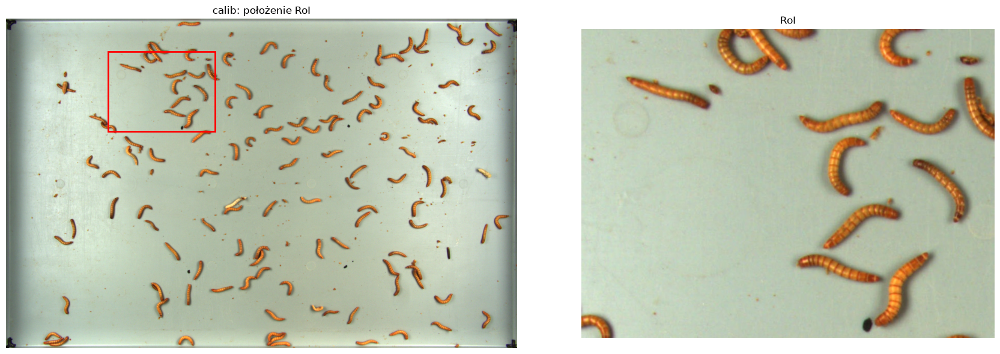

In [8]:
# Łatwy RoI: fragment calib z kilkunastoma larwami, w większości leżącymi osobno (współrzędne w układzie przyciętego obrazu)
roi = (slice(245, 845), slice(768, 1568))
roi_img = calib[roi]

f, (a1, a2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=(1.6, 1)))
a1.imshow(calib[..., ::-1])
a1.add_patch(plt.Rectangle((roi[1].start, roi[0].start), roi[1].stop - roi[1].start, roi[0].stop - roi[0].start,
                           fill=False, color='red', lw=2))
a1.set_title('calib: położenie RoI')
a2.imshow(roi_img[..., ::-1])
a2.set_title('RoI')
for ax in (a1, a2):
    ax.axis('off')
plt.tight_layout()

### Krok 1: binaryzacja wstępna, próg globalny na S (`rough_mask`)

**Binaryzacja wstępna** daje maskę wstępną: przybliżenie, które ma tylko wskazać, gdzie leżą obiekty (kandydaci i ich ROI w kroku 2). Jest szersza niż larwy, bo łapie poświatę, i bywa, że skleja sąsiadów. Ostateczny kształt każdej maski ustalają dopiero lokalny próg (krok 3) i erozja brzegu (krok 4).

Kanały dobieram za artykułem (sekcja III-B2c). Autorzy piszą, że larwy najwyraźniej oddzielają się od tła w **kanale S (nasycenie) modelu HSV** oraz w **kanale B modelu BGR**, i dlatego segmentują w tych dwóch kanałach:
* **S** służy do binaryzacji: najpierw próg globalny (ten krok), potem lokalny w każdym ROI (krok 3).
* **B** służy do doprecyzowania brzegów (adaptacyjna erozja, krok 4).

**Próg globalny na S.** W artykule dobrano go eksperymentalnie. Ja liczę go raz, metodą Otsu na obrazie kalibracyjnym (`S_THR`), i tej samej wartości używam dla RoI i obrazu testowego.

S_THR = 104; powyżej progu: calib 4.7%, test 5.1% pikseli


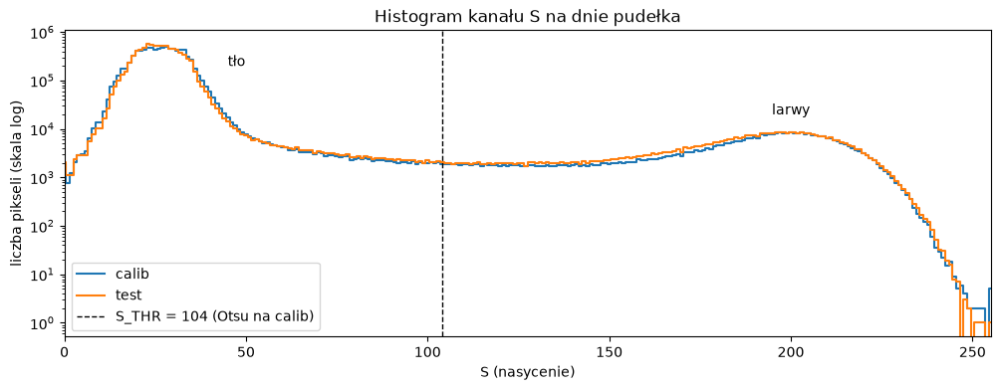

In [9]:
# Próg globalny na S: Otsu liczony raz, na obrazie kalibracyjnym. Ta sama wartość idzie do RoI i obrazu testowego.
S_calib = cv2.cvtColor(calib, cv2.COLOR_BGR2HSV)[..., 1]
S_test = cv2.cvtColor(test, cv2.COLOR_BGR2HSV)[..., 1]
S_THR, _ = cv2.threshold(S_calib, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f'S_THR = {S_THR:.0f}; powyżej progu: calib {(S_calib > S_THR).mean():.1%}, test {(S_test > S_THR).mean():.1%} pikseli')

# Histogram S na dnie pudełka; skala log, bo tło to ok. 95% pikseli
f, ax = plt.subplots(figsize=(12, 4))
for S, name in ((S_calib, 'calib'), (S_test, 'test')):
    ax.step(np.arange(256), np.bincount(S.ravel(), minlength=256), where='mid', lw=1.5, label=name)
ax.axvline(S_THR, color='k', ls='--', lw=1, label=f'S_THR = {S_THR:.0f} (Otsu na calib)')
ax.text(45, 2e5, 'tło', ha='left')
ax.text(200, 2e4, 'larwy', ha='center')
ax.set(yscale='log', xlim=(0, 255), xlabel='S (nasycenie)', ylabel='liczba pikseli (skala log)',
       title='Histogram kanału S na dnie pudełka')
ax.legend()

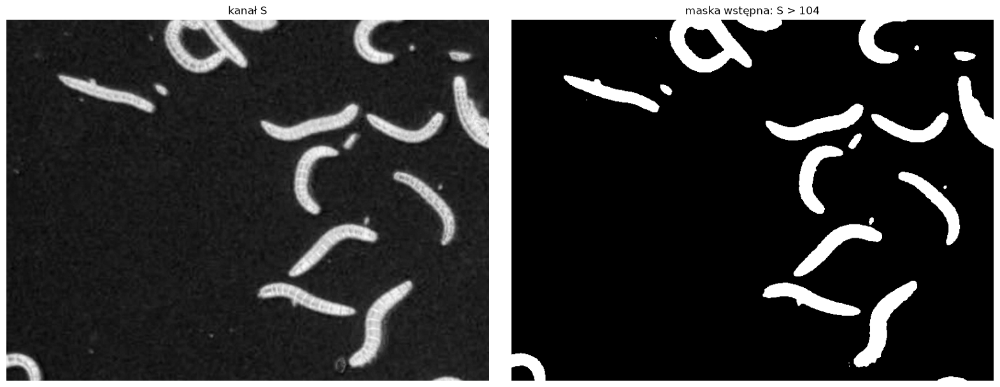

In [10]:
# Krok 1 na RoI: kanał S i maska wstępna
S_roi, rough_roi = rough_mask(roi_img, S_THR)
f, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(S_roi, cmap='gray')
axes[0].set_title('kanał S')
axes[1].imshow(rough_roi, cmap='gray')
axes[1].set_title(f'maska wstępna: S > {S_THR:.0f}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

#### Eksperyment: próg globalny a maska wstępna

Sprawdzam, co próg globalny robi z samą maską wstępną, czyli z wynikiem tego kroku. Liczę tylko kroki 1–2 dla progów 60–160 i śledzę:
* liczbę drobnych obiektów (< `min_area`), czyli szum, który krok 2 musi odrzucić,
* liczbę kandydatów o polu ponad 2× typowa larwa, czyli zlepków już w masce wstępnej,
* medianę pola kandydata, czyli ile poświaty wokół larw wchodzi do maski.

Pod wykresami: maska wstępna przy kilku progach na dwóch trudnych fragmentach `test`.

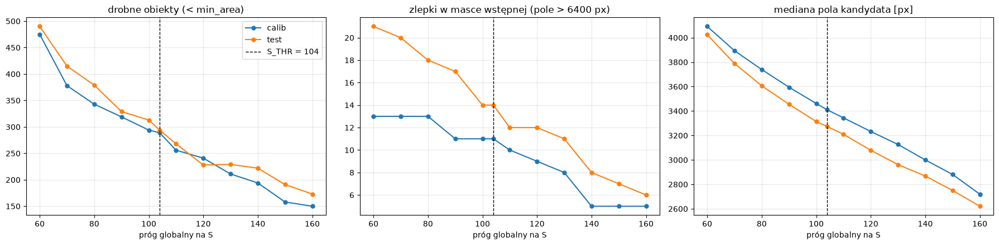

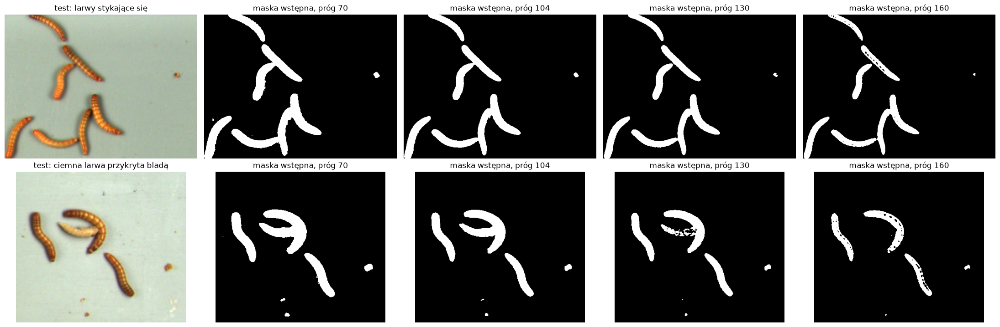

In [11]:
# Eksperyment (krok 1): jak próg globalny zmienia maskę wstępną. Liczone są tylko kroki 1-2, więc to szybkie.
CLUMP_AREA = 2 * 3200  # ok. 2 x mediana pola larwy po segmentacji: większy kandydat to prawie na pewno zlepek
thr_grid = sorted({60, 70, 80, 90, 100, S_THR, 110, 120, 130, 140, 150, 160})
f, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, img in (('calib', calib), ('test', test)):
    stats = []
    for t in thr_grid:
        seeds, small = find_candidates(rough_mask(img, t)[1])
        areas = [cv2.contourArea(s['contour']) for s in seeds]
        stats.append((len(small), sum(a > CLUMP_AREA for a in areas), np.median(areas)))
    for ax, values in zip(axes, zip(*stats)):
        ax.plot(thr_grid, values, 'o-', lw=1.5, ms=5, label=name)
for ax, title in zip(axes, ('drobne obiekty (< min_area)', f'zlepki w masce wstępnej (pole > {CLUMP_AREA} px)',
                            'mediana pola kandydata [px]')):
    ax.axvline(S_THR, color='k', ls='--', lw=1, label=f'S_THR = {S_THR:.0f}')
    ax.set(title=title, xlabel='próg globalny na S')
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()

# Maska wstępna przy kilku progach na dwóch trudnych fragmentach test
zooms = [('larwy stykające się', (slice(20, 470), slice(1320, 1920))),
         ('ciemna larwa przykryta bladą', (slice(1320, 1720), slice(2970, 3420)))]
shown_thr = (70, S_THR, 130, 160)
f, axes = plt.subplots(len(zooms), len(shown_thr) + 1, figsize=(4.4 * (len(shown_thr) + 1), 3.6 * len(zooms)))
for row, (label, zoom) in zip(axes, zooms):
    row[0].imshow(test[zoom][..., ::-1])
    row[0].set_title(f'test: {label}')
    for ax, t in zip(row[1:], shown_thr):
        ax.imshow(rough_mask(test[zoom], t)[1], cmap='gray')
        ax.set_title(f'maska wstępna, próg {t:.0f}')
    for ax in row:
        ax.axis('off')
plt.tight_layout()

**Wniosek (krok 1):**
* **Niski próg (≤ 80)** wpuszcza do maski poświatę wokół larw. Mediana pola kandydata rośnie z ok. 3400 px (przy `S_THR`) do ok. 4100 px (przy 60), drobnych obiektów jest ok. 1.7× więcej, a sąsiednie larwy łączą się przez poświatę w zlepki.
* **Wysoki próg** rozcina zlepki: przy 160 jest ich w masce wstępnej 5 zamiast 11 (`calib`) i 6 zamiast 14 (`test`). Kosztem jest to, że blade larwy rozpadają się na kawałki, a przy 160 maski nawet ciemnych larw mają dziury i przerwy.
* Kandydatów o polu ≥ `min_area` jest prawie tyle samo przy każdym progu (`calib` 102–105, `test` 111–115). Próg globalny nie decyduje więc o tym, *czy* larwa zostanie znaleziona. Decyduje o tym, jak dzielą się zlepki i ile tła wchodzi do maski. Kształt maski i tak ustala później lokalny próg (krok 3).
* Ile z tego zostaje po całym potoku, sprawdzam w sekcji „Wrażliwość wyniku na próg globalny”.

### Krok 2: komponenty spójności i filtr pola (`find_candidates`)

Kontury zewnętrzne maski wstępnej (`cv2.findContours`, `RETR_EXTERNAL`) wyznaczają komponenty spójności. Komponenty o polu `< min_area` to okruchy, odchody i fragmenty wylinek. Odrzucam je od razu, tak jak w artykule („mniejsze niż pojedynczy owad”). Wokół każdego pozostałego komponentu wyznaczam prostokątne ROI z marginesem `margin` = 10 px. W nim działają kroki 3–4.

(np.float64(-0.5), np.float64(799.5), np.float64(599.5), np.float64(-0.5))

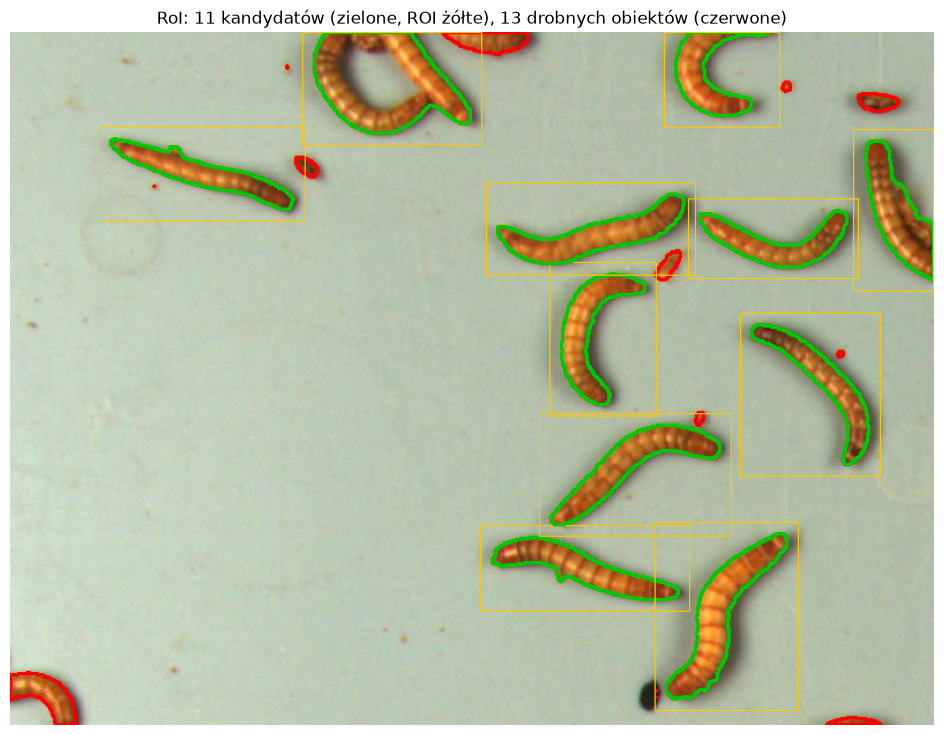

In [12]:
# Krok 2 na RoI: zielone = kandydaci (pole >= min_area) z prostokątem ROI, czerwone = drobne obiekty
seeds_roi, small_roi = find_candidates(rough_roi)
vis = np.ascontiguousarray(roi_img[..., ::-1]).copy()
cv2.drawContours(vis, small_roi, -1, (255, 0, 0), 2)
for s in seeds_roi:
    cv2.drawContours(vis, [s['contour']], -1, (0, 200, 0), 2)
    x0, y0, x1, y1 = s['roi']
    cv2.rectangle(vis, (x0, y0), (x1 - 1, y1 - 1), (255, 200, 0), 1)
f, ax = plt.subplots(figsize=(12, 9))
ax.imshow(vis)
ax.set_title(f'RoI: {len(seeds_roi)} kandydatów (zielone, ROI żółte), {len(small_roi)} drobnych obiektów (czerwone)')
ax.axis('off')

calib: komponentów o polu 1000-1700 px: 0, największy drobny: 956 px, najmniejszy kandydat: 1966 px
test: komponentów o polu 1000-1700 px: 0, największy drobny: 821 px, najmniejszy kandydat: 1729 px


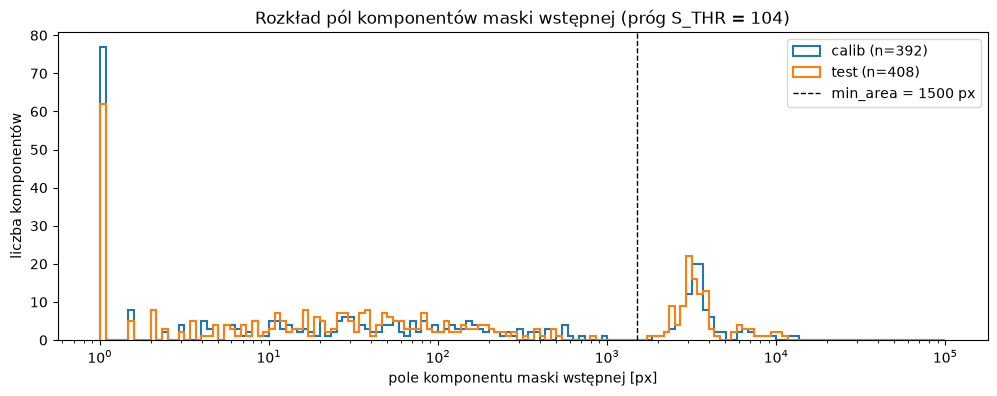

In [13]:
# Uzasadnienie min_area: rozkład pól wszystkich komponentów maski wstępnej (oś x w skali log, 30 przedziałów na dekadę)
bins = np.logspace(0, 5, 151)
f, ax = plt.subplots(figsize=(12, 4))
for name, img in (('calib', calib), ('test', test)):
    cnts, _ = cv2.findContours(rough_mask(img, S_THR)[1], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    areas = np.array([cv2.contourArea(c) for c in cnts])
    ax.hist(np.maximum(areas, 1), bins, histtype='step', lw=1.5, label=f'{name} (n={len(areas)})')
    print(f'{name}: komponentów o polu 1000-1700 px: {np.sum((areas >= 1000) & (areas < 1700))}, '
          f'największy drobny: {areas[areas < 1500].max():.0f} px, najmniejszy kandydat: {areas[areas >= 1500].min():.0f} px')
ax.axvline(1500, color='k', ls='--', lw=1, label='min_area = 1500 px')
ax.set(xscale='log', xlabel='pole komponentu maski wstępnej [px]', ylabel='liczba komponentów',
       title=f'Rozkład pól komponentów maski wstępnej (próg S_THR = {S_THR:.0f})')
ax.legend()

**Wniosek (krok 2):** rozkład pól jest dwumodalny. Drobne obiekty mają najwyżej ok. 960 px, a najmniejszy kandydat ok. 1730 px. Między nimi nie ma na żadnym obrazie ani jednego komponentu. `min_area` = 1500 px leży więc w przerwie i jego dokładna wartość nie ma znaczenia. Pojedyncze larwy mają po segmentacji ok. 1800–4300 px. Na RoI czerwone są też fragmenty larw przeciętych brzegiem RoI, bo ich część wewnątrz RoI ma mniej niż `min_area`.

### Kroki 3–4: segmentacja w ROI (`segment_candidate`)

Dla każdego kandydata, w jego ROI:
* **krok 3:** lokalny próg Otsu na S. Histogram ROI zawiera głównie jedną larwę i tło wokół niej, więc Otsu wyznacza próg dopasowany do tej larwy. Wynik ograniczam do konturu wstępnego poszerzonego o ok. 3 px (`K_GROW`), żeby lokalny próg nie skleił z powrotem larw, które rozdzielił próg globalny. Fragmenty sąsiednich larw, które wpadły do prostokąta ROI, odpadają na końcu, bo zostaje tylko składowa nakładająca się na kontur wstępny.
* **krok 4:** adaptacyjna erozja brzegu na kanale B (`refine_edges`). Larwy są żółto-brązowe, czyli mają mało niebieskiego, więc piksel brzegowy z jasnym B to piksel mieszany z tłem albo poświata. Usuwam go, gdy średnia B w jego otoczeniu 3×3 przekracza średnią B obiektu o więcej niż `delta`. Artykuł nie podaje wartości `delta`. Nie przyjmuję stałej, tylko liczę ją dla każdego ROI: `delta` = `alpha` × kontrast, gdzie kontrast to mediana B tła w ROI (piksele co najmniej 4 px od maski) minus średnia B obiektu (`b_contrast`). Pudełko jest oświetlone nierówno, więc kontrast różni się między larwami prawie trzykrotnie (eksperyment niżej), a stała `delta` erodowałaby larwy na jasnym tle mocniej niż na ciemnym. Parametrem jest więc `alpha`: jaka część kontrastu larwa–tło wystarczy, żeby piksel brzegowy uznać za tło. Brzeg wyznaczam kwadratowym elementem strukturalnym 3×3 (piksel jest brzegowy, gdy którykolwiek z 8 sąsiadów należy do tła), więc jedna iteracja zdejmuje najwyżej 1 px, a `refine_iters` = 4 ogranicza erozję do 4 px.
* Na koniec zostaje największa składowa pokrywająca się z konturem wstępnym, z wypełnionymi dziurami.

Poniżej trzech kandydatów z RoI krok po kroku.

lokalne progi Otsu w RoI:

 [103, 107, 111, 112, 112, 112, 113, 113, 114, 114, 115] (globalny S_THR = 104)


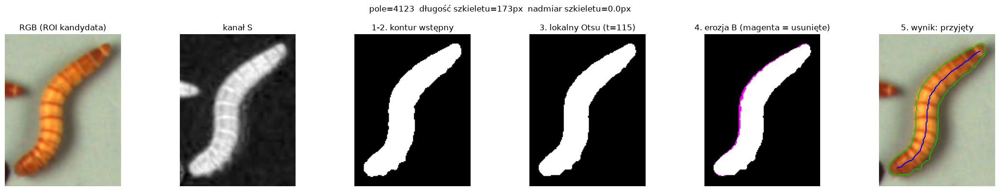

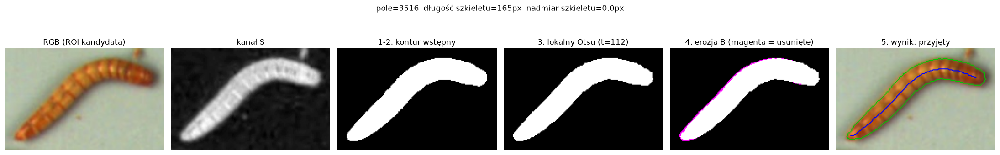

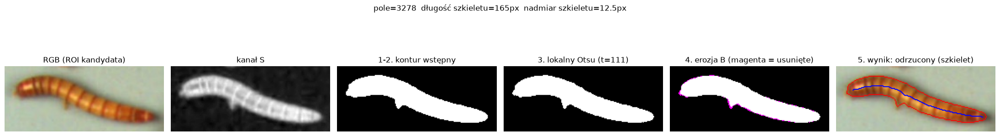

In [14]:
# Kroki 3-4 na RoI: detect_objects z debug=True zapisuje obrazy pośrednie każdego kandydata
objs_roi, dbg_roi = detect_objects(roi_img, S_THR, debug=True)
print('lokalne progi Otsu w RoI:', sorted(round(c['local_thr']) for c in dbg_roi['candidates']),
      f'(globalny S_THR = {S_THR:.0f})')
shown = [c for c in dbg_roi['candidates'] if c['reason'] is None][:2] + [c for c in dbg_roi['candidates'] if c['reason']][:1]
for cand in shown:
    show_candidate_steps(roi_img, cand)

#### Eksperyment: siła erozji brzegu (`alpha`)

Najpierw sprawdzam, czy stała `delta` ma sens: liczę kontrast B tło − larwa w ROI wszystkich kandydatów. Potem liczę erozję wprost funkcją `refine_edges` na masce z kroku 3 dwóch larw z RoI, dla trzech wartości `alpha` (mniejsza `alpha` = mocniejsza erozja). Półprzezroczysta zieleń to maska po erozji, a niebieska linia to kontur maski z kroku 3 (po binaryzacji lokalnym Otsu). Pas między konturem a zielenią to dokładnie piksele zdjęte przez erozję, a wszystko w zieleni zostaje w masce. Na koniec przebieg `alpha` od 0.05 do 0.5 na całym potoku dla obu obrazów: odsetek zdjętych pikseli (wynik kroku 4) oraz liczba przyjętych larw i mediana ich grubości (wynik końcowy).

calib: kontrast B tło - larwa w ROI kandydatów: min 64, mediana 121, max 169; stała delta=30 to alpha od 0.18 do 0.47


test: kontrast B tło - larwa w ROI kandydatów: min 62, mediana 126, max 170; stała delta=30 to alpha od 0.18 do 0.48


alpha | calib: larwy  zdjęto  grubość | test: larwy  zdjęto  grubość
 0.05 |          73   26.5%    15.79 |          85   25.2%    15.59
 0.10 |          72   19.0%    18.00 |          88   17.6%    17.58
 0.15 |          82   13.1%    19.58 |          97   11.9%    19.58
 0.20 |          82    8.7%    20.38 |          99    8.0%    20.38
 0.25 |          86    5.6%    21.19 |          97    5.1%    21.19
 0.30 |          87    3.4%    21.58 |         100    3.1%    21.58
 0.35 |          86    1.9%    21.97 |         100    1.6%    21.97
 0.40 |          85    1.0%    21.98 |         100    0.7%    21.97
 0.45 |          84    0.5%    22.00 |         101    0.2%    21.97
 0.50 |          84    0.3%    22.00 |         101    0.0%    21.97


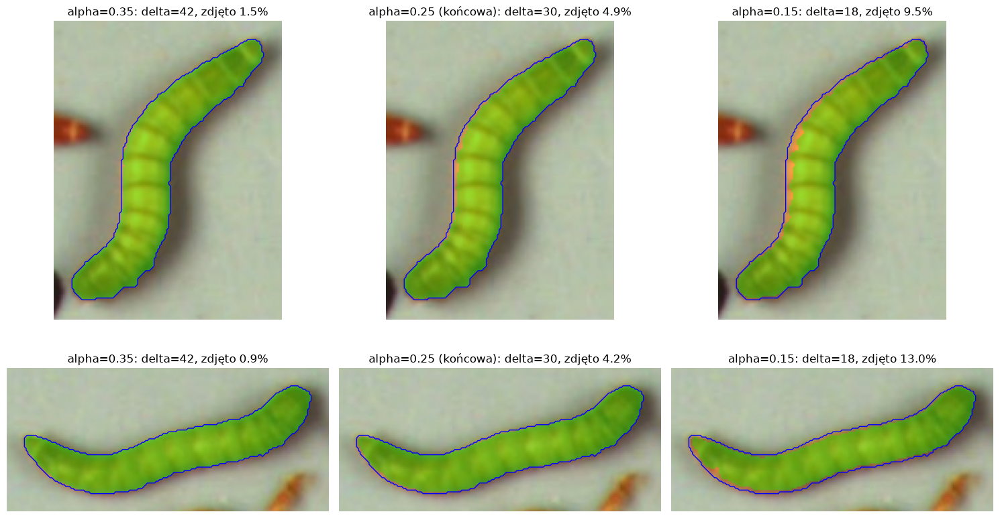

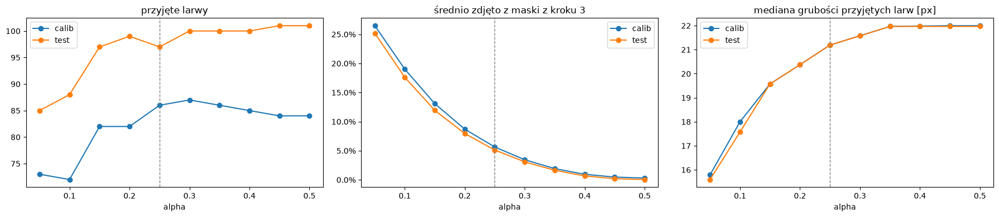

In [15]:
# Eksperyment (krok 4): alpha, czyli jaka część kontrastu B tło - larwa decyduje o usunięciu piksela brzegowego.
# Detekcja trwa ułamek sekundy, więc przebieg alpha liczę na całym potoku dla obu obrazów.
ALPHA_SHOW = [('alpha=0.35', 0.35), ('alpha=0.25 (końcowa)', 0.25), ('alpha=0.15', 0.15)]
ALPHA_GRID = np.round(np.arange(0.05, 0.51, 0.05), 2)


def show_erosion(ax, img_roi: np.ndarray, local: np.ndarray, eroded: np.ndarray):
    """Maska po erozji jako półprzezroczysta zieleń, kontur maski z kroku 3 na niebiesko.
    Pas między konturem a zielenią to piksele zdjęte przez erozję."""
    vis = img_roi[..., ::-1].astype(np.float32)
    vis[eroded > 0] = 0.6 * vis[eroded > 0] + 0.4 * np.array([0, 255, 0])
    ax.imshow(vis.astype(np.uint8))
    for cnt in find_contours(local, 0.5):  # kontur po granicy pikseli
        ax.plot(cnt[:, 1], cnt[:, 0], color='blue', lw=1)
    ax.axis('off')


def roi_of(image: np.ndarray, cand: dict):
    x0, y0, x1, y1 = cand['roi']
    return image[y0:y1, x0:x1]


# a) po co delta zależna od ROI: kontrast B tło - larwa w ROI kandydatów (maska z kroku 3, nie zależy od alpha)
for name, image in (('calib', calib), ('test', test)):
    _, dbg = detect_objects(image, S_THR, debug=True)
    con = np.array([b_contrast(c['steps']['local'], roi_of(image, c)[..., 0]) for c in dbg['candidates']])
    print(f'{name}: kontrast B tło - larwa w ROI kandydatów: min {con.min():.0f}, mediana {np.median(con):.0f}, '
          f'max {con.max():.0f}; stała delta=30 to alpha od {30 / con.max():.2f} do {30 / con.min():.2f}')

# b) dwie larwy z RoI dla trzech wartości alpha
examples = sorted((c for c in dbg_roi['candidates'] if c['reason'] is None), key=lambda c: -c['area'])[:2]
f, axes = plt.subplots(len(examples), len(ALPHA_SHOW), figsize=(5 * len(ALPHA_SHOW), 4.5 * len(examples)), squeeze=False)
for row, cand in zip(axes, examples):
    local, img_roi = cand['steps']['local'], roi_of(roi_img, cand)
    con = b_contrast(local, img_roi[..., 0])
    for ax, (name, a) in zip(row, ALPHA_SHOW):
        eroded = refine_edges(local, img_roi[..., 0], a)
        show_erosion(ax, img_roi, local, eroded)
        ax.set_title(f'{name}: delta={a * con:.0f}, zdjęto {1 - eroded.sum() / local.sum():.1%}')
plt.tight_layout()

# c) przebieg alpha na całym potoku: odsetek zdjętych pikseli, liczba larw, mediana grubości przyjętych larw
sweep = {}
for name, image in (('calib', calib), ('test', test)):
    for a in ALPHA_GRID:
        objs, dbg = detect_objects(image, S_THR, refine_alpha=a, debug=True)
        removed = np.mean([1 - c['steps']['refined'].sum() / c['steps']['local'].sum() for c in dbg['candidates']])
        sweep[name, a] = (len(objs), removed, np.median([o['width_est'] for o in objs]))
print('alpha | calib: larwy  zdjęto  grubość | test: larwy  zdjęto  grubość')
for a in ALPHA_GRID:
    print(f' {a:.2f} |' + ' |'.join(f'{sweep[n, a][0]:12d} {sweep[n, a][1]:7.1%} {sweep[n, a][2]:8.2f}'
                                   for n in ('calib', 'test')))
f, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, j, t in zip(axes, range(3), ['przyjęte larwy', 'średnio zdjęto z maski z kroku 3', 'mediana grubości przyjętych larw [px]']):
    for n in ('calib', 'test'):
        ax.plot(ALPHA_GRID, [sweep[n, a][j] for a in ALPHA_GRID], 'o-', label=n)
    ax.axvline(0.25, color='gray', ls='--', lw=1)
    ax.set_xlabel('alpha')
    ax.set_title(t)
    ax.legend()
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()

#### Stała `delta` a `delta` dopasowana do ROI

Przy `alpha` = 0.25 erozja jest średnio tak silna jak przy stałej `delta` = 30, której używałem wcześniej: dla mediany kontrastu (ok. 120) daje właśnie `delta` = 30. Decyzja filtra zmienia się jednak dla dwóch kandydatów. Poniżej oba: po lewej stała `delta` = 30 (czyli `alpha` = 30 / kontrast), po prawej `alpha` = 0.25.

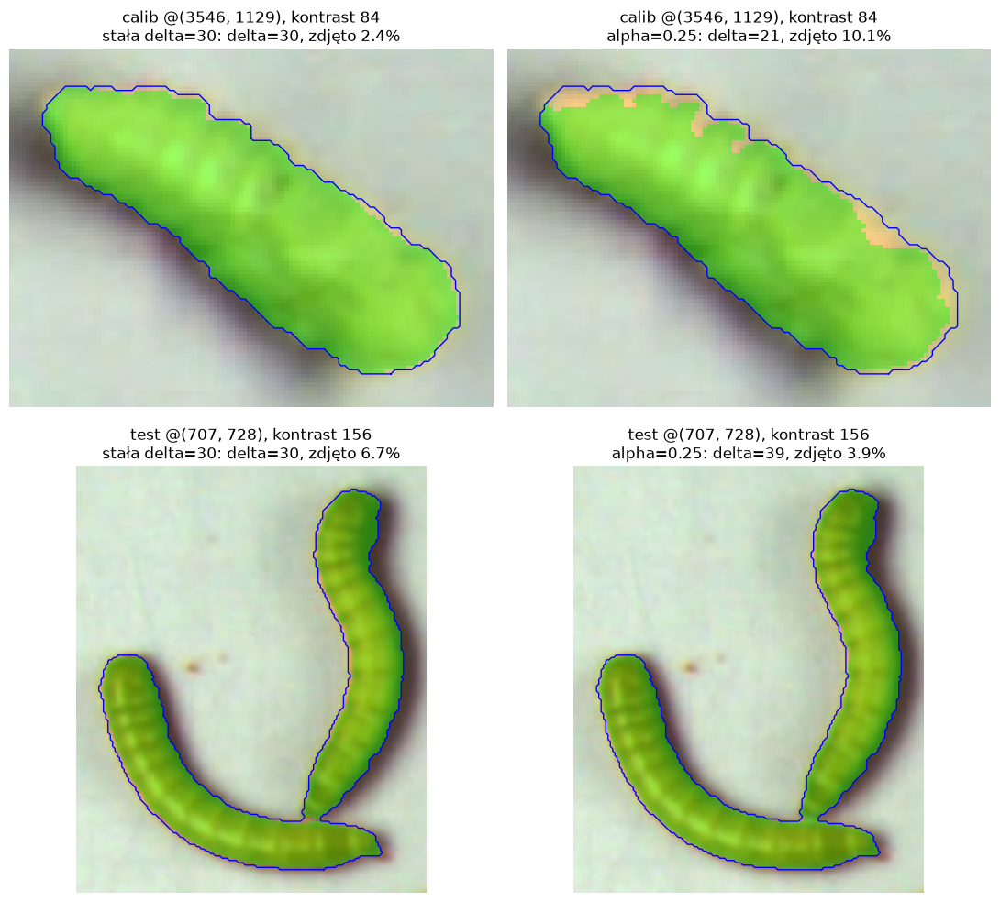

In [16]:
# Stała delta = 30 (czyli alpha = 30 / kontrast) a alpha = 0.25 na dwóch kandydatach, dla których zmienia się decyzja
# filtra. Punkt (x, y) w układzie przyciętego obrazu leży w ROI kandydata.
cases = [('calib', calib, (3596, 1162)), ('test', test, (768, 846))]
f, axes = plt.subplots(len(cases), 2, figsize=(11, 5 * len(cases)), squeeze=False)
for row, (name, image, (px, py)) in zip(axes, cases):
    _, dbg = detect_objects(image, S_THR, debug=True)
    cand = max((c for c in dbg['candidates'] if c['roi'][0] <= px < c['roi'][2] and c['roi'][1] <= py < c['roi'][3]),
               key=lambda c: c['area'])
    local, img_roi = cand['steps']['local'], roi_of(image, cand)
    con = b_contrast(local, img_roi[..., 0])
    for ax, (t, a) in zip(row, [('stała delta=30', 30 / con), ('alpha=0.25', 0.25)]):
        eroded = refine_edges(local, img_roi[..., 0], a)
        show_erosion(ax, img_roi, local, eroded)
        ax.set_title(f'{name} @{cand["bbox"][:2]}, kontrast {con:.0f}\n{t}: delta={a * con:.0f}, zdjęto {1 - eroded.sum() / local.sum():.1%}')
plt.tight_layout()

**Wniosek (kroki 3–4):**
* Lokalne progi Otsu w RoI wynoszą 103–115, czyli są równe progowi globalnemu albo trochę wyższe. Krok 3 w praktyce przycina więc maskę wstępną: zdejmuje resztki poświaty i rozcina połączenia dwóch larw przez poświatę (wtedy zostaje tylko największa część).
* **Kontrast B tło − larwa** w ROI kandydatów wynosi 64–169 na `calib` i 62–170 na `test` (mediana 121 / 126). Larwy mają podobne B, zmienia się głównie tło, bo pudełko jest oświetlone nierówno. Stała `delta` = 30 to więc od 0.18 do 0.48 kontrastu: na jasnym tle erozja zdejmuje piksele z niewielką domieszką tła, a na ciemnym dopiero takie, które są prawie w połowie tłem. Dlatego `delta` liczę z kontrastu w ROI.
* **`alpha` na RoI:** przy 0.35 erozja zdejmuje pojedyncze piksele (ok. 1–1.5% maski). Przy 0.25 zdejmuje wąski pas jasnych pikseli po stronie oświetlonej, tam gdzie brzeg larwy płynnie przechodzi w tło (ok. 4–5%). Przy 0.15 pas jest szeroki i wcina się w ciało larwy: między konturem a zielenią widać pomarańczowe piksele (ok. 10–13%). Od strony cienia kontur z kroku 3 leży już na brzegu ciała, bo cień ma niskie S, więc tam erozja nie ma czego zdejmować.
* **Przebieg `alpha` na całym potoku:** odsetek zdjętych pikseli maleje płynnie od ok. 26% przy 0.05 do zera przy 0.5, bez wyraźnego kolana, więc wartości nie da się odczytać z samej krzywej. Mediana grubości rośnie do ok. 22.0 px przy 0.4 i dalej się nie zmienia, a przy 0.25 wynosi 21.2 px. Liczba larw po całym potoku zależy od `alpha` bardziej niż sama maska: dla 0.25–0.50 jest to 84–87 na `calib` i 97–101 na `test`, a przy mocniejszej erozji (≤ 0.20) spada (72–82 i 85–99). Mocna erozja wycina w brzegu wcięcia, przez które szkielet dostaje boczne gałęzie, a krok 5 przepuszcza tylko larwy bez gałęzi (`max_extra` = 3 px). Przy 0.30 przechodzi o 1 larwę więcej na `calib` i o 3 na `test`: to larwy z drobnym guzkiem, który przy słabszej erozji nie tworzy gałęzi.
* **Wybieram `alpha` = 0.25.** Dla mediany kontrastu daje `delta` ≈ 30, czyli wartość, którą wcześniej dobrałem wzrokowo jako stałą, i średnio zdejmuje tyle samo pikseli (5.6% / 5.1%). Różnica polega na tym, że erozja nie zależy już od jasności tła w danym miejscu pudełka.
* **Stała `delta` a `alpha` = 0.25** (dwa kandydaty wyżej):
  * `calib` @(3546, 1129): blada, krótka larwa, najpewniej tuż po wylince, z kontrastem 84. Stała `delta` = 30 zostawiała jasną poświatę i larwa odpadała przez `grubosc` (1.48×). Teraz `delta` = 21 zdejmuje poświatę i grubość spada do 1.19×. Maska ma jednak wcięcia w jasnych miejscach ciała i boczną gałąź szkieletu, więc larwa i tak odpada przez `szkielet` (`max_extra` = 3 px).
  * `test` @(707, 728): dwie larwy stykające się końcem z bokiem, na jasnym tle (kontrast 156). Stała `delta` = 30 przecinała wąską szyjkę między nimi, a reguła największej składowej zostawiała tylko większą larwę. Przy `alpha` = 0.25 (`delta` = 39) szyjka zostaje, więc filtr odrzuca parę jako `szkielet`. Rozdzielenie było przypadkowym skutkiem silniejszej erozji na jasnym tle. Teraz parę rozdziela krok 6 i odzyskuje obie larwy.

### Krok 5: opis blobu i filtracja (`blob_features`, `filter_candidates`)

Z maski każdego kandydata `blob_features` liczy przybliżone cechy kształtu:
* szkielet wygładzonej maski i jego **najdłuższą ścieżkę**, wyznaczaną dwoma przebiegami „najdalszego punktu” (`skimage.graph.MCP_Geometric`),
* **nadmiar** = całkowita długość szkieletu (`skimage.graph.pixel_graph`) − najdłuższa ścieżka,
* przybliżoną grubość = 2 × transformata odległości na środku ścieżki.

Te cechy służą tylko do decyzji „jedna larwa czy nie”. Dokładny pomiar długości robi dopiero moduł analizy instancji.

`filter_candidates` odrzuca kandydata z pierwszym pasującym powodem:
* `krawedz`: obiekt dotyka brzegu obrazu (prostokąta `FLOOR`) lub RoI, więc może być ucięty albo wchodzić na ściankę;
* `szkielet`: nadmiar ≥ `max_extra` = 3 px, czyli szkielet ma boczną gałąź: skrzyżowane albo zlepione larwy oraz larwy z przyklejoną wypustką (okruch, wylinka). Część z nich poprawia krok 6;
* `dlugosc`: najdłuższa ścieżka > `k_len` × mediana, czyli larwy stykające się końcami (mają czysty szkielet, ale podwójną długość);
* `grubosc`: grubość > `k_width` × mediana, czyli larwy sklejone bokiem, leżące równolegle (szkielet też mają czysty);
* `pole`: pole > `k_area` × mediana, czyli zabezpieczenie na zlepki, których nie złapały poprzednie reguły.

Progi `dlugosc`, `grubosc` i `pole` są **względne**: odnoszą się do mediany „czystych” kandydatów (bez rozgałęzień, nie na krawędzi), więc dopasowują się do rozmiaru larw w danej partii. Uzasadnienie `max_extra` i progów względnych jest niżej.

RoI: 7 larw, odrzucono: {'szkielet': 1, 'krawedz': 3}
mediany z RoI: pole 2921 px, długość 165 px, grubość 20.0 px


<Axes: title={'center': 'RoI: 7 larw, 4 odrzuconych'}>

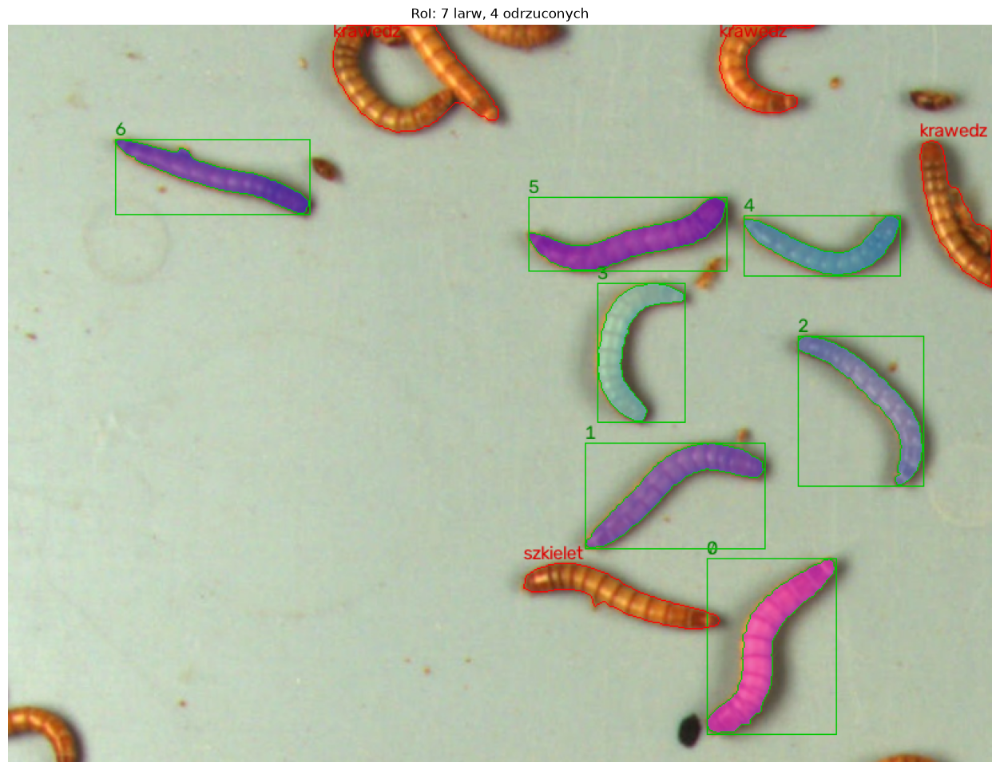

In [17]:
# Krok 5 na RoI: zielone = przyjęte, czerwone = odrzucone z powodem; mediany liczone z samego RoI
print(f"RoI: {len(objs_roi)} larw, odrzucono: {dict(Counter(c['reason'] for c in dbg_roi['rejected']))}")
print(f"mediany z RoI: pole {dbg_roi['ref_area']:.0f} px, długość {dbg_roi['ref_len']:.0f} px, grubość {dbg_roi['ref_width']:.1f} px")
display_objects(roi_img, objs_roi, mode='both', rejected=dbg_roi['rejected'],
                title=f'RoI: {len(objs_roi)} larw, {len(dbg_roi["rejected"])} odrzuconych')

Na RoI nie ma zlepków, więc filtr dobierałem na wszystkich kandydatach z `calib`. `test` służy do sprawdzenia, czy wnioski się przenoszą. Detekcję na obu obrazach (kroki 1–6) liczę tutaj, a wyniki pokazuję w sekcjach „Wynik”. Eksperymenty z filtrem korzystają z kandydatów po kroku 5. Krok 6 opisuję w osobnej sekcji po kroku 5.

In [18]:
# Pełna detekcja na obu obrazach (kroki 1-6, parametry końcowe). Eksperymenty z filtrem korzystają z kandydatów
# po kroku 5 (dbg['candidates']), a krok 6 opisuję w osobnej sekcji niżej.
objs_calib, dbg_calib = detect_objects(calib, S_THR, debug=True)
objs_test, dbg_test = detect_objects(test, S_THR, debug=True)
print(f'calib: {len(dbg_calib["candidates"])} kandydatów, test: {len(dbg_test["candidates"])} kandydatów')

calib: 103 kandydatów, test: 114 kandydatów


#### Eksperyment: jak powstał filtr zlepków (`max_extra`)

**Pierwsza wersja** uznawała obiekt za pojedynczą larwę, gdy jego szkielet ma dokładnie 2 końce i 0 rozgałęzień. Odrzucała jednak także larwy z drobnym okruchem przyklejonym do brzegu, bo okruch tworzy krótką boczną gałązkę szkieletu.

**Druga próba:** przycinanie krótkich gałązek. Nie pomogło, bo po usunięciu gałązki przy węźle zostawały 1–2-pikselowe resztki, które dalej liczyły się jako końce.

**Trzecia wersja:** zamiast liczyć węzły mierzę **nadmiar**, czyli łączną długość szkieletu poza najdłuższą ścieżką, i odrzucałem obiekt dopiero przy nadmiarze ≥ 30 px. Krótka wypustka daje mały nadmiar, a druga larwa duży. Larwy z okruchem przechodziły, ale okruch zostawał w masce.

**Wersja końcowa:** `max_extra` = 3 px, czyli larwa przechodzi krok 5 tylko bez bocznej gałęzi. Nadmiaru od 0 do 3 px nie ma żaden kandydat (larwy bez gałęzi mają 0, z gałęzią co najmniej 4 px), więc 1–2-pikselowe resztki szkieletu nie przeszkadzają, a decyzje są takie same jak w pierwszej wersji. Różnica polega na tym, że larwa z wypustką nie przepada od razu: trafia do kroku 6, który usuwa wypustkę wyższym progiem na S albo larwę odrzuca. Wolę zgubić larwę niż zapisać maskę z okruchem.

Poniżej: rozkład nadmiaru oraz larwy, które przy dawnym progu 30 px przechodziły razem z małą wypustką, po dwa panele na larwę:
* **pierwsza reguła:** biały kontur to maska wygładzona otwarciem 7×7, z której powstaje szkielet (cyjan). Koniec (żółty) to piksel szkieletu z jednym sąsiadem w oknie 3×3. Rozgałęzienie (magenta) to skupisko stykających się pikseli z co najmniej trzema sąsiadami: jedno rozwidlenie daje zwykle 3–4 takie piksele, więc liczę skupiska, a nie piksele.
* **wynik końcowy:** maska, która trafia do wyników. Zielony kontur: wypustkę usunął krok 6 (biała przerywana linia to maska z kroku 5). Czerwony kontur: larwa odpada, bo krok 6 nie umiał usunąć wypustki. Niebieska linia to najdłuższa ścieżka, a pomarańczowe piksele to boczne gałęzie (nadmiar).

pierwsza reguła (2 końce, 0 rozgałęzień) i nadmiar < 3 px: ta sama decyzja dla 103 z 103 kandydatów calib
larwy z małą wypustką (przy max_extra = 30 przyjęte): 10; krok 6 usuwa wypustkę u 4, pozostałe odpadają


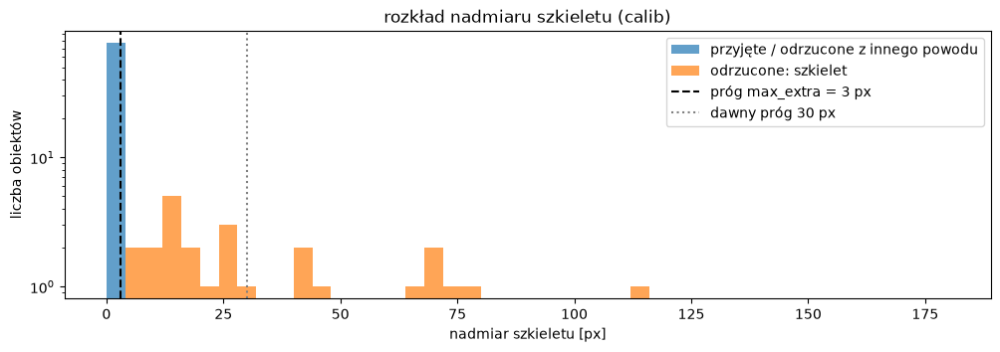

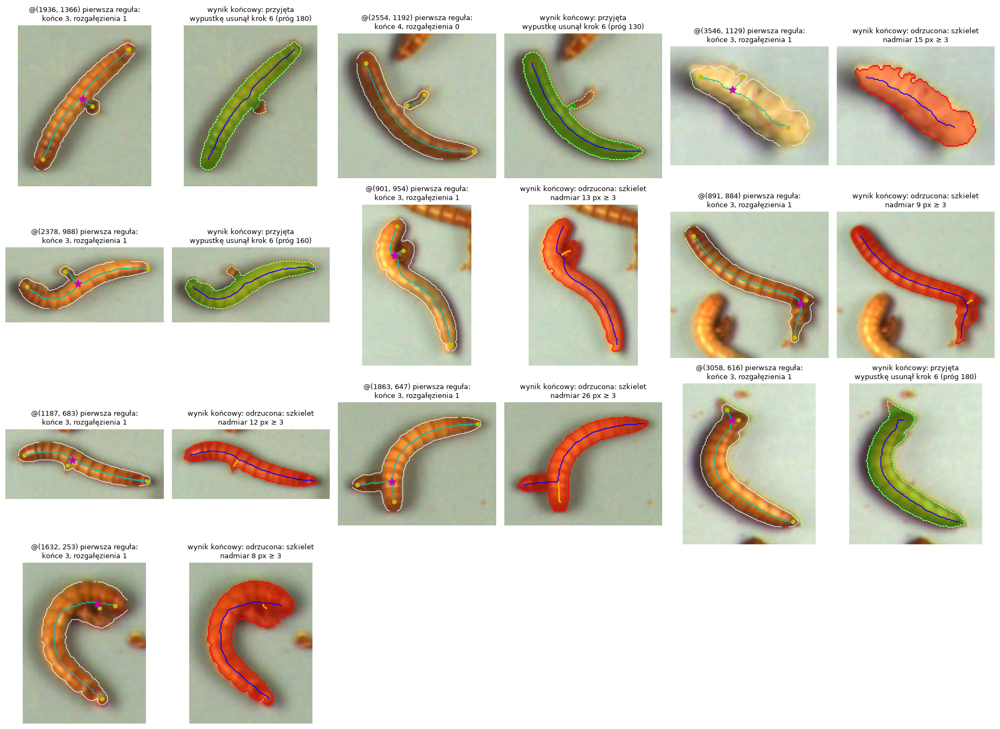

In [19]:
K3 = np.ones((3, 3), np.float32)


def skeleton_nodes(mask: np.ndarray):
    """Szkielet, z którego blob_features liczy nadmiar (smooth_skeleton), oraz jego końce i rozgałęzienia.
    Liczba sąsiadów piksela szkieletu = suma okna 3x3 (8-sąsiedztwo) minus on sam.
    Koniec = piksel z 1 sąsiadem. Rozgałęzienie = skupisko stykających się pikseli z >= 3 sąsiadami: jedno
    rozwidlenie szkieletu 8-spójnego daje zwykle 3-4 takie piksele, więc liczę skupiska, a nie piksele.
    Zwraca (szkielet, maska końców, środki rozgałęzień jako tablica (N, 2) [x, y])."""
    _, sk = smooth_skeleton(mask)
    sk = sk.astype(np.uint8)
    nbrs = cv2.filter2D(sk, -1, K3, borderType=cv2.BORDER_CONSTANT).astype(int) - 1
    _, _, _, centers = cv2.connectedComponentsWithStats(((nbrs >= 3) & (sk > 0)).astype(np.uint8), connectivity=8)
    return sk, (nbrs == 1) & (sk > 0), centers[1:]


def crop_around(image: np.ndarray, c: dict, pad: int):
    """Wycinek RGB wokół bbox kandydata i położenie (x0, y0) wycinka w obrazie."""
    x, y, w, h = c['bbox']
    x0, y0 = max(x - pad, 0), max(y - pad, 0)
    return np.ascontiguousarray(image[y0:y + h + pad, x0:x + w + pad, ::-1]).copy(), x0, y0


def show_gallery(image: np.ndarray, cands: List, title_fn, cols: int = 6, pad: int = 15):
    """Galeria wycinków z konturem (zielony = przyjęty, czerwony = odrzucony).
    image: obraz albo słownik {nazwa: obraz}; wtedy obraz wycinka wybiera pole c['img_name']."""
    if not cands:
        print('(brak obiektów)')
        return
    rows = int(np.ceil(len(cands) / cols))
    f, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, c in zip(axes.ravel(), cands):
        crop, x0, y0 = crop_around(image[c['img_name']] if isinstance(image, dict) else image, c, pad)
        cv2.drawContours(crop, [c['contour'] - [x0, y0]], -1, REJECT_RGB if c.get('reason') else ACCEPT_RGB, 1)
        ax.imshow(crop)
        ax.set_title(title_fn(c), fontsize=9)
    plt.tight_layout()


def show_skeleton_vs_final(image: np.ndarray, cands: List, splits: List = (), cols: int = 3, pad: int = 15,
                           max_extra: float = 3.0):
    """Dwa panele na kandydata.
    Lewy, „pierwsza reguła”: maska wygładzona otwarciem (biały kontur), z której powstaje szkielet (cyjan),
    końce (żółte) i rozgałęzienia (magenta). Bez decyzji, więc bez konturu zielonego / czerwonego.
    Prawy, „wynik końcowy”: maska, która trafia do wyników (półprzezroczysta), kontur w kolorze decyzji,
    najdłuższa ścieżka (niebieska) i gałęzie liczone do nadmiaru (pomarańczowe). Jeśli kandydata zmienił krok 6
    (`splits` z detect_objects), panel pokazuje maskę po kroku 6, a biała przerywana linia to maska z kroku 5."""
    by_cand = {id(s['cand']): s for s in splits}
    rows = int(np.ceil(len(cands) / cols))
    f, axes = plt.subplots(rows, 2 * cols, figsize=(3.1 * 2 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for k, c in enumerate(cands):
        a_rule, a_final = axes[k // cols, 2 * (k % cols)], axes[k // cols, 2 * (k % cols) + 1]
        crop, x0, y0 = crop_around(image, c, pad)
        ox, oy = c['bbox'][0] - x0, c['bbox'][1] - y0  # położenie maski w wycinku
        smooth, _ = smooth_skeleton(c['mask'])
        sk, ends, junctions = skeleton_nodes(c['mask'])

        a_rule.imshow(crop)
        for cnt in find_contours(smooth, 0.5):
            a_rule.plot(cnt[:, 1] + ox, cnt[:, 0] + oy, '-', color='white', lw=0.8)
        for m_, style, ms in ((sk, 'c.', 1.5), (ends, 'yo', 5)):
            yy, xx = np.nonzero(m_)
            a_rule.plot(xx + ox, yy + oy, style, ms=ms)
        a_rule.plot(junctions[:, 0] + ox, junctions[:, 1] + oy, 'm*', ms=10)
        a_rule.set_title(f"@({c['bbox'][0]}, {c['bbox'][1]}) pierwsza reguła:\n"
                         f"końce {ends.sum()}, rozgałęzienia {len(junctions)}", fontsize=9)

        split = by_cand.get(id(c))
        shown = split['parts'] if split else [c]
        for o in shown:  # wypełnienie i kontur w kolorze decyzji
            m = o['mask'] > 0
            bx, by = o['bbox'][0] - x0, o['bbox'][1] - y0
            verdict = ACCEPT_RGB if o['reason'] is None else REJECT_RGB
            region = crop[by:by + m.shape[0], bx:bx + m.shape[1]]
            region[m] = (0.65 * region[m] + 0.35 * np.array(verdict)).astype(np.uint8)
            cv2.drawContours(crop, [o['contour'] - [x0, y0]], -1, verdict, 1)
        a_final.imshow(crop)
        if split:
            cnt = c['contour'][:, 0, :] - [x0, y0]
            a_final.plot(np.r_[cnt[:, 0], cnt[0, 0]], np.r_[cnt[:, 1], cnt[0, 1]], '--', color='white', lw=0.8)
        for o in shown:  # najdłuższa ścieżka i gałęzie nadmiaru
            bx, by = o['bbox'][0] - x0, o['bbox'][1] - y0
            _, sk_o = smooth_skeleton(o['mask'])
            on_path = np.zeros(sk_o.shape, bool)
            on_path[o['skeleton_path'][:, 0], o['skeleton_path'][:, 1]] = True
            yy, xx = np.nonzero(sk_o & ~on_path)
            a_final.plot(xx + bx, yy + by, '.', color='orange', ms=3)
            a_final.plot(o['skeleton_path'][:, 1] + bx, o['skeleton_path'][:, 0] + by, '-', color='blue', lw=1.2)
        if split:
            title = f"wynik końcowy: przyjęta\nwypustkę usunął krok 6 (próg {split['thr']})"
        else:
            title = (f"wynik końcowy: {'przyjęta' if c['reason'] is None else 'odrzucona: ' + c['reason']}\n"
                     f"nadmiar {c['skeleton_extra']:.0f} px {'<' if c['skeleton_extra'] < max_extra else '≥'} {max_extra:.0f}")
        a_final.set_title(title, fontsize=9)
    plt.tight_layout()


def old_rule_ok(c) -> bool:
    _, ends, junctions = skeleton_nodes(c['mask'])
    return ends.sum() == 2 and len(junctions) == 0


cands = [c for c in dbg_calib['candidates'] if not c['touches_border']]
same = sum(old_rule_ok(c) == (c['skeleton_extra'] < 3) for c in cands)
print(f'pierwsza reguła (2 końce, 0 rozgałęzień) i nadmiar < 3 px: ta sama decyzja dla {same} z {len(cands)} kandydatów calib')

# Larwy, które przy dawnym progu max_extra = 30 px przechodziły razem z małą wypustką (nadmiar >= 3 px)
old, _ = filter_candidates(dbg_calib['candidates'], max_extra=30)
small = [c for c, o in zip(dbg_calib['candidates'], old) if o['reason'] is None and c['skeleton_extra'] >= 3]
cleaned = {id(s['cand']) for s in dbg_calib['splits']}
print(f"larwy z małą wypustką (przy max_extra = 30 przyjęte): {len(small)}; krok 6 usuwa wypustkę u "
      f"{sum(id(c) in cleaned for c in small)}, pozostałe odpadają")

f, ax = plt.subplots(figsize=(12, 3.5))
bins = np.arange(0, 181, 4)
ax.hist([c['skeleton_extra'] for c in cands if c['reason'] != 'szkielet'], bins, alpha=0.7,
        label='przyjęte / odrzucone z innego powodu')
ax.hist([c['skeleton_extra'] for c in cands if c['reason'] == 'szkielet'], bins, alpha=0.7, label='odrzucone: szkielet')
ax.axvline(3, color='k', ls='--', label='próg max_extra = 3 px')
ax.axvline(30, color='gray', ls=':', label='dawny próg 30 px')
ax.set_yscale('log'); ax.set_xlabel('nadmiar szkieletu [px]'); ax.set_ylabel('liczba obiektów'); ax.legend()
ax.set_title('rozkład nadmiaru szkieletu (calib)')

show_skeleton_vs_final(calib, small, dbg_calib['splits'])

#### Uzasadnienie progów względnych (`k_len`, `k_width`, `k_area`)

Dla każdego kandydata, który przeszedł reguły `krawedz` i `szkielet`, liczę stosunek długości, grubości i pola do mediany jego obrazu. Próg względny ma sens, jeśli między pojedynczymi larwami a zlepkami jest przerwa i próg w niej leży. Kolor punktu oznacza ostateczną decyzję filtra. Pod wykresem są przypadki graniczne: najwyższe wartości wśród przyjętych i najniższe ponad progiem, żeby ocenić wzrokowo, co jest pojedynczą larwą.

Czego się spodziewać po budowie zlepka:
* dwie larwy stykające się końcami mają długość ≈ L₁ + L₂, czyli ok. 2× mediana; dla dwóch małych larw mniej, nawet ok. 1.2–1.4×;
* dwie larwy leżące równolegle mogą mieć w środku nawet 2× grubość, ale zwykle stykają się tylko fragmentem, więc mediana grubości na środku osi rośnie mniej;
* pole zlepka to ok. 2× mediana minus część wspólna.

długość  próg 1.35: przyjęte do 1.25 (95. percentyl 1.13); ponad progiem 2 kandydatów, od 1.47; reguła zadziałała jako pierwsza 2 razy
grubość  próg 1.25: przyjęte do 1.20 (95. percentyl 1.11); ponad progiem 1 kandydatów, od 1.32; reguła zadziałała jako pierwsza 1 razy
pole     próg 1.6: przyjęte do 1.34 (95. percentyl 1.20); ponad progiem 1 kandydatów, od 1.80; reguła zadziałała jako pierwsza 0 razy


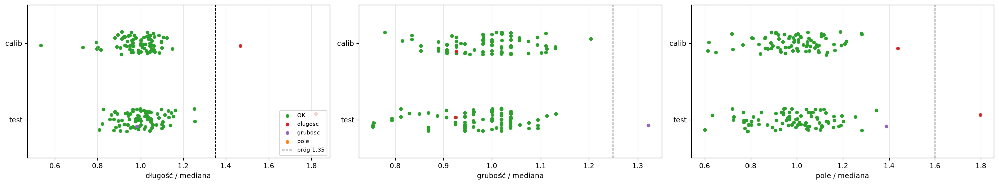

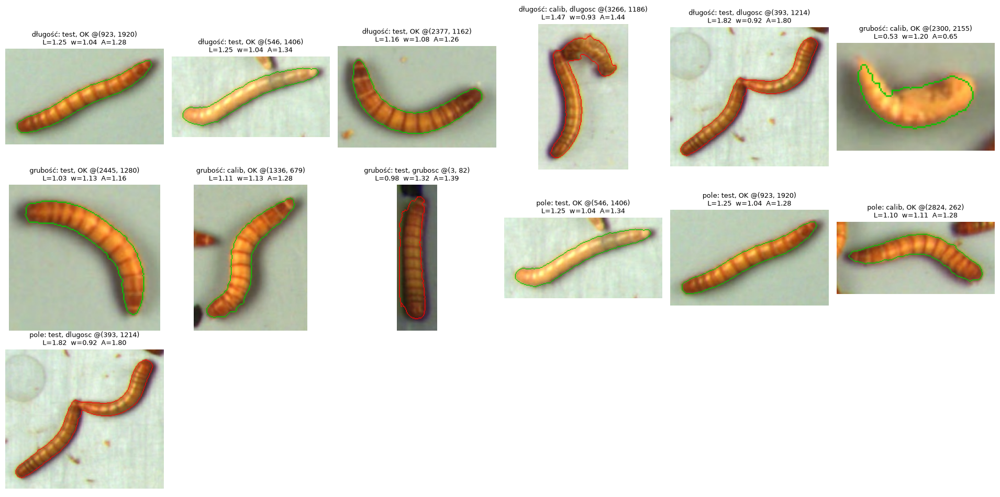

In [20]:
# Stosunek do mediany dla kandydatów, o których decydują progi względne (po regułach krawedz i szkielet)
criteria = [('length_px', 'ref_len', 1.35, 'długość'), ('width_est', 'ref_width', 1.25, 'grubość'),
            ('area', 'ref_area', 1.6, 'pole')]
pool = [dict(c, img_name=name, ratios={key: c[key] / dbg[ref] for key, ref, _, _ in criteria})
        for name, dbg in (('calib', dbg_calib), ('test', dbg_test))
        for c in dbg['candidates'] if c['reason'] not in ('maly', 'krawedz', 'szkielet')]
REASON_COLORS = {'OK': 'tab:green', 'dlugosc': 'tab:red', 'grubosc': 'tab:purple', 'pole': 'tab:orange'}

rng = np.random.default_rng(1)
f, axes = plt.subplots(1, 3, figsize=(20, 3.8))
for ax, (key, _, k, label) in zip(axes, criteria):
    for row, name in enumerate(('test', 'calib')):
        for reason, col in REASON_COLORS.items():
            vals = [c['ratios'][key] for c in pool if c['img_name'] == name and (c['reason'] or 'OK') == reason]
            ax.scatter(vals, row + rng.uniform(-0.15, 0.15, len(vals)), s=18, color=col,
                       label=reason if row == 1 else None)
    ax.axvline(k, color='k', ls='--', lw=1, label=f'próg {k}')
    ax.set(yticks=[0, 1], yticklabels=['test', 'calib'], xlabel=f'{label} / mediana', ylim=(-0.5, 1.5))
    ax.grid(alpha=0.3, axis='x')
axes[0].legend(fontsize=8, loc='lower right')
plt.tight_layout()

for key, _, k, label in criteria:
    ok = [c['ratios'][key] for c in pool if c['reason'] is None]
    above = [c['ratios'][key] for c in pool if c['ratios'][key] > k]
    fired = sum(c['reason'] == {'length_px': 'dlugosc', 'width_est': 'grubosc', 'area': 'pole'}[key] for c in pool)
    print(f'{label:8s} próg {k}: przyjęte do {max(ok):.2f} (95. percentyl {np.percentile(ok, 95):.2f}); '
          f'ponad progiem {len(above)} kandydatów, od {min(above):.2f}; reguła zadziałała jako pierwsza {fired} razy')

# Przypadki graniczne: po 3 najwyższe wśród przyjętych i 3 najniższe ponad progiem, osobno dla każdej cechy
cases = []
for key, _, k, label in criteria:
    ok = sorted((c for c in pool if c['reason'] is None), key=lambda c: -c['ratios'][key])[:3]
    above = sorted((c for c in pool if c['ratios'][key] > k), key=lambda c: c['ratios'][key])[:3]
    cases += [dict(c, crit=label) for c in ok + above]
show_gallery({'calib': calib, 'test': test}, cases, cols=6,
             title_fn=lambda c: (f"{c['crit']}: {c['img_name']}, {c['reason'] or 'OK'} @({c['bbox'][0]}, {c['bbox'][1]})\n"
                                 f"L={c['ratios']['length_px']:.2f}  w={c['ratios']['width_est']:.2f}  "
                                 f"A={c['ratios']['area']:.2f}"))

#### Próg długości: dlaczego 1.35, a nie 1.5

Pierwotnie `k_len` wynosiło 1.5. Wykres pokazuje, ile larw przyjmuje filtr przy różnych wartościach `k_len`, przy pozostałych regułach bez zmian. `filter_candidates` działa na gotowych cechach, więc segmentacji nie trzeba powtarzać. Pod wykresem: kandydat, dla którego progi 1.5 i 1.35 dają różną decyzję.

calib: przy k_len = 1.35 przyjętych 76, przy 1.5: 77; ta sama liczba dla k_len 1.15-1.46
test: przy k_len = 1.35 przyjętych 82, przy 1.5: 82; ta sama liczba dla k_len 1.26-2.30
decyzja zmienia się dla 1 kandydatów


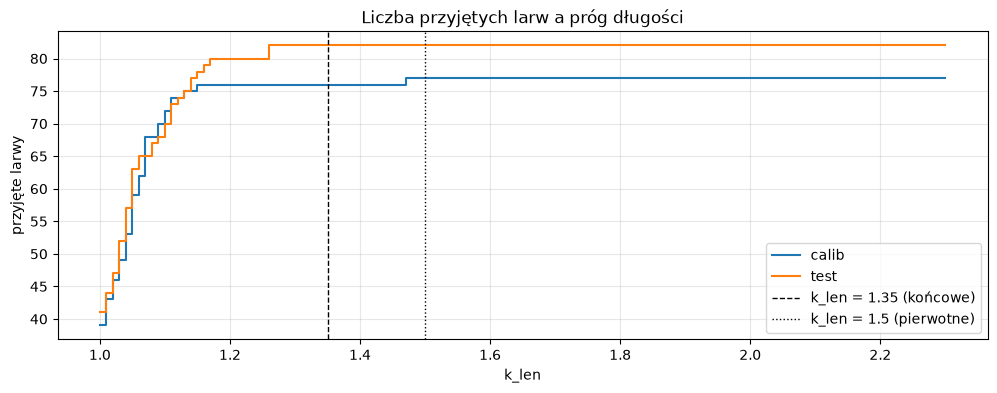

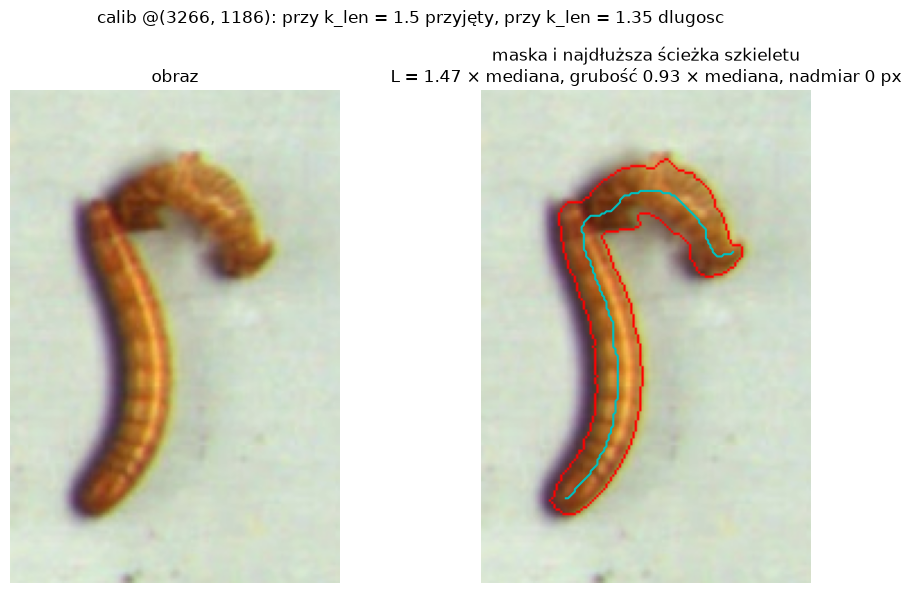

In [21]:
# Liczba przyjętych larw w funkcji k_len (pozostałe reguły bez zmian), na gotowych kandydatach z detekcji
k_grid = np.round(np.arange(1.0, 2.31, 0.01), 2)
f, ax = plt.subplots(figsize=(12, 4))
for name, dbg in (('calib', dbg_calib), ('test', dbg_test)):
    n_ok = [sum(c['reason'] is None for c in filter_candidates(dbg['candidates'], k_len=k)[0]) for k in k_grid]
    ax.step(k_grid, n_ok, where='post', lw=1.5, label=name)
    plateau = k_grid[np.array(n_ok) == n_ok[list(k_grid).index(1.35)]]
    print(f'{name}: przy k_len = 1.35 przyjętych {n_ok[list(k_grid).index(1.35)]}, przy 1.5: {n_ok[list(k_grid).index(1.5)]}; '
          f'ta sama liczba dla k_len {plateau.min():.2f}-{plateau.max():.2f}')
for k, style, label in ((1.35, '--', 'k_len = 1.35 (końcowe)'), (1.5, ':', 'k_len = 1.5 (pierwotne)')):
    ax.axvline(k, color='k', ls=style, lw=1, label=label)
ax.set(xlabel='k_len', ylabel='przyjęte larwy', title='Liczba przyjętych larw a próg długości')
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(alpha=0.3)
ax.legend()

# Kandydaci, dla których k_len = 1.5 i k_len = 1.35 dają różną decyzję
changed = []
for name, img, dbg in (('calib', calib, dbg_calib), ('test', test, dbg_test)):
    at_15, _ = filter_candidates(dbg['candidates'], k_len=1.5)
    at_135, _ = filter_candidates(dbg['candidates'], k_len=1.35)
    changed += [(name, img, dbg, c15, c135) for c15, c135 in zip(at_15, at_135) if c15['reason'] != c135['reason']]
print(f'decyzja zmienia się dla {len(changed)} kandydatów')
for name, img, dbg, c15, c135 in changed:
    x, y, w, h = c135['bbox']
    pad = 30
    x0, y0 = max(x - pad, 0), max(y - pad, 0)
    crop = np.ascontiguousarray(img[y0:y + h + pad, x0:x + w + pad, ::-1]).copy()
    f, (a1, a2) = plt.subplots(1, 2, figsize=(10, 6))
    a1.imshow(crop)
    a1.set_title('obraz')
    cv2.drawContours(crop, [c135['contour'] - [x0, y0]], -1, (255, 0, 0), 1)
    a2.imshow(crop)
    path = c135['skeleton_path']
    a2.plot(path[:, 1] + x - x0, path[:, 0] + y - y0, 'c-', lw=1.5)
    a2.set_title(f"maska i najdłuższa ścieżka szkieletu\nL = {c135['length_px'] / dbg['ref_len']:.2f} × mediana, "
                 f"grubość {c135['width_est'] / dbg['ref_width']:.2f} × mediana, nadmiar {c135['skeleton_extra']:.0f} px")
    for ax in (a1, a2):
        ax.axis('off')
    f.suptitle(f"{name} @({x}, {y}): przy k_len = 1.5 {c15['reason'] or 'przyjęty'}, przy k_len = 1.35 {c135['reason'] or 'przyjęty'}")
    plt.tight_layout()

**Wniosek:**
* **Długość (`k_len` = 1.35).** Pojedyncze larwy mają do 1.25× mediany (95. percentyl ok. 1.1×), a zlepki stykające się końcami od 1.47×. Najkrótszy zlepek to obiekt z `calib` @(3266, 1186): **dwie larwy**, prosta i zwinięta, stykające się końcami. Ma czysty szkielet (nadmiar 0), a najdłuższa ścieżka biegnie przez obie larwy. Jest też cieńszy od mediany (0.94×), więc pozostałe reguły go przepuszczają. Pierwotny próg 1.5 leżał tuż nad nim, więc ten zlepek trafiał do wyników jako pojedyncza larwa. Próg 1.35 leży w środku przerwy 1.25–1.47. Dla `k_len` od 1.26 do 1.46 liczba przyjętych larw na obu obrazach się nie zmienia (wykres), więc dokładna wartość w tym zakresie nie ma znaczenia. Granica nie może być ostra: dwie małe larwy (po ok. 0.6×) dają razem tyle, co długa pojedyncza larwa.
* **Grubość (`k_width` = 1.25).** Pojedyncze larwy mają do 1.20× (krótka, skurczona larwa w `calib`). Powyżej progu jest tylko larwa leżąca przy lewej ściance `test` (1.32×): jej maska obejmuje rozmyty cień na ściance. Zlepki sklejone bokiem, które przy dawnym progu nadmiaru (30 px) łapała grubość (od 1.26×), mają boczną gałąź i odpadają wcześniej przez `szkielet`. Blada, krótka larwa z `calib` @(3546, 1129) przy stałej `delta` = 30 odpadała tu z grubością 1.48×, bo maska obejmowała poświatę. Po dopasowaniu `delta` do ROI ma 1.19×, ale odpada przez `szkielet` (kroki 3–4).
* **Pole (`k_area` = 1.6).** Pole nie oddziela pojedynczych larw od zlepków. Duże pojedyncze larwy mają do ok. 1.34× mediany, a przy dawnym progu nadmiaru (30 px) dwie larwy sklejone bokiem miały już od 1.23×, bo częściowo na siebie nachodzą. Na obu obrazach reguła `pole` nie zadziałała ani razu jako pierwsza: każdy kandydat powyżej 1.6× odpada wcześniej przez `szkielet` albo `dlugosc`. Zostawiam ją jako zabezpieczenie. To pokazuje też, dlaczego sam filtr pola, czyli najprostsza alternatywa, by nie wystarczył: myli rozmiar larwy z liczbą larw.
* **Skutek uboczny progów względnych:** reguły `dlugosc` i `grubosc` z definicji obcinają górny ogon rozkładu długości, którą potem mierzę. Na tych obrazach pojedyncze larwy kończą się wyraźnie poniżej progów, więc to nie przeszkadza. W partii o większym rozrzucie rozmiarów te reguły wycięłyby jednak największe osobniki. Reguła `szkielet` nie zależy od rozmiaru i tej wady nie ma.

### Krok 6: rozdzielanie zlepków i usuwanie wypustek (`split_candidates`)

Krok 5 odrzuca w całości każdy obiekt z boczną gałęzią szkieletu oraz obiekty za długie i za grube. Część z nich da się poprawić: zlepki rozdzielić na larwy, a z larwy z przyklejonym okruchem, kawałkiem wylinki albo odchodem usunąć tę wypustkę. Obie sytuacje mają podobną budowę: dwa obiekty łączy wąski mostek z pikseli mieszanych, o niższym S niż ciało larwy. Wyższy próg na S rozcina takie mostki (wniosek z kroku 1), ale podniesiony dla całego obrazu gubi blade larwy (sekcja o wrażliwości niżej). Dlatego podnoszę go tylko w obrębie maski jednego kandydata.

Krok 6 dostaje kandydatów odrzuconych w kroku 5 jako `szkielet`, `dlugosc` albo `grubosc`. Dla każdego kandydata `split_candidate` sprawdza progi na S co 10 (`thr_step`), od pierwszego powyżej progu lokalnego z kroku 3 do 200. Przy każdym progu `clump_parts` robi:
1. progowanie S w obrębie maski kandydata,
2. otwarcie elipsą 5×5 (`open_k`), które przecina cienkie mostki,
3. składowe ≥ 500 px (`min_part`) jako znaczniki; mniejsze to okruchy i odpadają,
4. odbudowę każdego znacznika o 6 px (`grow`) funkcją `skimage.segmentation.expand_labels`, tylko w granicach maski kandydata. Wyższy próg działa jak erozja, a to jest operacja odwrotna: dylatacja, w której piksel trafia do najbliższego znacznika, więc sąsiednie larwy się nie sklejają.

Przyjmuję najniższy próg, przy którym podział jest poprawny:
* każda część przechodzi filtr z kroku 5 (z medianami całego obrazu), więc m.in. nie ma bocznej gałęzi szkieletu,
* każda część ma długość ≥ 0.7 × mediana (`k_min`). Krótsza część to najpewniej kawałek larwy przykrytej przez inną,
* części razem pokrywają ≥ 94% maski kandydata (`min_cover`). Inaczej wysoki próg uciął albo zjadł kawałek larwy, np. koniec, brzeg albo larwę bledszą, której fragment został doklejony do sąsiadki. Do maski kandydata nie liczę usuniętych kawałków, które stykały się z częściami na mniej niż `k_neck` = 0.5 × mediana grubości (ok. 10 px). Taki kawałek łączył się wąską szyjką, więc był osobnym obiektem (okruch, wylinka, inna larwa), a nie fragmentem larwy (`split_cover`).

Jeśli żaden próg nie daje poprawnego podziału, kandydat zostaje odrzucony. Tak jak w całym potoku: lepiej zgubić larwę niż zapisać złą maskę.

Krok 6 liczy `detect_objects`, więc jego wynik jest już w `objs_calib` i `objs_test` (komórka z pełną detekcją w kroku 5). Na RoI krok 6 niczego nie zmienia, więc niżej są całe obrazy.

calib: 76 larw po kroku 5 -> 86 po kroku 6; z 27 kandydatów odrzuconych jako zlepki: 3 rozdzielone (+6 larw), 4 larw bez wypustki
  zlepek   @(1759, 1867) (szkielet, nadmiar 19 px): próg 190, części 2, L = 0.89, 1.06 x mediana, pokrycie 0.99
  zlepek   @(2835, 1810) (szkielet, nadmiar 5 px): próg 170, części 2, L = 1.08, 0.97 x mediana, pokrycie 1.00
  wypustka @(1936, 1366) (szkielet, nadmiar 14 px): próg 180, części 1, L = 0.90 x mediana, pokrycie 0.97
  wypustka @(2554, 1192) (szkielet, nadmiar 18 px): próg 130, części 1, L = 0.85 x mediana, pokrycie 1.00
  wypustka @(2378, 988) (szkielet, nadmiar 23 px): próg 160, części 1, L = 1.02 x mediana, pokrycie 0.96
  zlepek   @(2356, 723) (szkielet, nadmiar 46 px): próg 150, części 2, L = 0.93, 0.98 x mediana, pokrycie 1.00
  wypustka @(3058, 616) (szkielet, nadmiar 9 px): próg 180, części 1, L = 0.95 x mediana, pokrycie 0.98
test: 82 larw po kroku 5 -> 97 po kroku 6; z 32 kandydatów odrzuconych jako zlepki: 5 rozdzielone (+10 larw), 5 lar

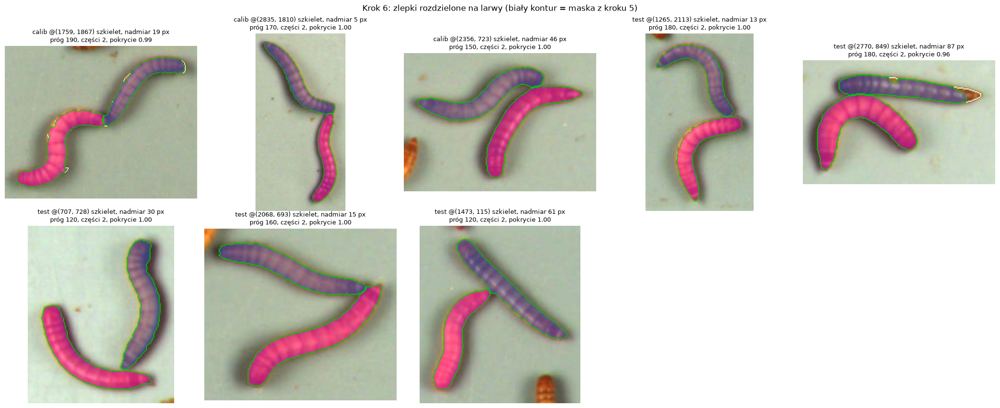

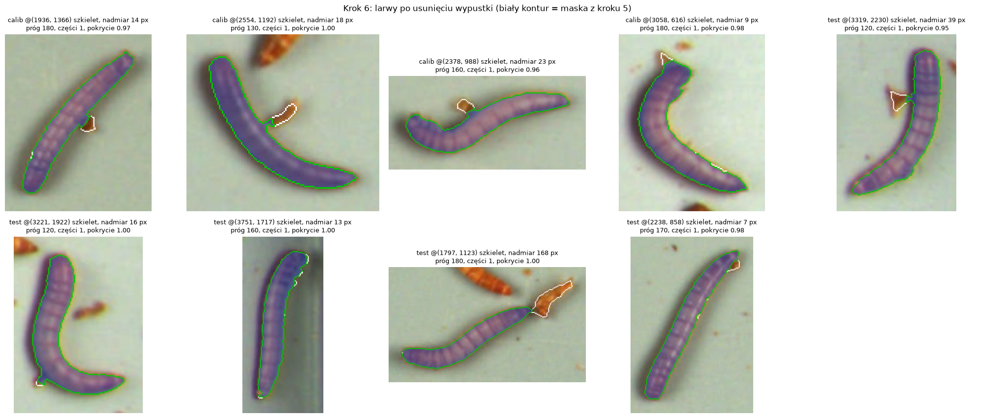

In [22]:
SPLIT_FILLS = [(40, 90, 255), (255, 0, 255), (0, 220, 255), (255, 230, 0)]  # bez czerwieni i zieleni


def show_splits(image, splits: List, title_fn=None, cols: int = 4, pad: int = 15, title: str = None,
                accepted: bool = True):
    """Galeria wyników kroku 6: wycinek kandydata, biały kontur = maska z kroku 5, każda część innym kolorem
    wypełnienia, kontur części w kolorze decyzji: zielony = podział przyjęty, czerwony = odrzucony (`accepted=False`).
    image: obraz albo słownik {nazwa: obraz}; wtedy obraz wybiera pole s['img_name']."""
    if not splits:
        print('(brak podziałów)')
        return
    rows = int(np.ceil(len(splits) / cols))
    f, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, s in zip(axes.ravel(), splits):
        c = s['cand']
        crop, x0, y0 = crop_around(image[s['img_name']] if isinstance(image, dict) else image, c, pad)
        overlay = crop.copy()
        for k, p in enumerate(s['parts']):
            cv2.drawContours(overlay, [p['contour'] - [x0, y0]], -1, SPLIT_FILLS[k % len(SPLIT_FILLS)], -1)
        crop = cv2.addWeighted(overlay, 0.4, crop, 0.6, 0)
        cv2.drawContours(crop, [c['contour'] - [x0, y0]], -1, (255, 255, 255), 1)
        for p in s['parts']:
            cv2.drawContours(crop, [p['contour'] - [x0, y0]], -1, ACCEPT_RGB if accepted else REJECT_RGB, 1)
        ax.imshow(crop)
        ax.set_title(title_fn(s) if title_fn else
                     f"{s.get('img_name', '')} @({c['bbox'][0]}, {c['bbox'][1]}) {c['reason'] or 'przyjęta'}, "
                     f"nadmiar {c['skeleton_extra']:.0f} px\npróg {s['thr']}, części {len(s['parts'])}, pokrycie {s['cover']:.2f}",
                     fontsize=9)
    plt.tight_layout()
    if title:
        f.suptitle(title, y=1.01)


# Wynik kroku 6 (policzony w detect_objects razem z krokami 1-5, komórka z pełną detekcją w kroku 5)
images, infos = {'calib': calib, 'test': test}, {'calib': dbg_calib, 'test': dbg_test}
for (name, info), objs in zip(infos.items(), (objs_calib, objs_test)):
    n5 = sum(c['reason'] is None for c in info['candidates'])
    clumps = [s for s in info['splits'] if s['kind'] == 'zlepek']
    cleaned = [s for s in info['splits'] if s['kind'] == 'wypustka']
    n_clumps = sum(c['reason'] in CLUMP_REASONS for c in info['candidates'])
    print(f"{name}: {n5} larw po kroku 5 -> {len(objs)} po kroku 6; z {n_clumps} kandydatów odrzuconych jako zlepki: "
          f"{len(clumps)} rozdzielone (+{sum(len(s['parts']) for s in clumps)} larw), {len(cleaned)} larw bez wypustki")
    for s in info['splits']:
        c = s['cand']
        L = [p['length_px'] / info['ref_len'] for p in s['parts']]
        print(f"  {s['kind']:8s} @{c['bbox'][:2]} ({c['reason']}, nadmiar {c['skeleton_extra']:.0f} px): "
              f"próg {s['thr']}, części {len(s['parts'])}, L = {', '.join(f'{l:.2f}' for l in L)} x mediana, pokrycie {s['cover']:.2f}")

for kind, label in (('zlepek', 'zlepki rozdzielone na larwy'), ('wypustka', 'larwy po usunięciu wypustki')):
    show_splits(images, [dict(s, img_name=name) for name, info in infos.items() for s in info['splits'] if s['kind'] == kind],
                cols=5, title=f'Krok 6: {label} (biały kontur = maska z kroku 5)')

#### Eksperyment: parametry kroku 6 i zabezpieczenia

Zmieniam po jednym parametrze (pozostałe mają wartości końcowe). W tabeli: liczba larw po kroku 6 i liczba zmian (podziałów zlepków albo usuniętych wypustek), które różnią się od wersji końcowej, razem dla obu obrazów. Krok 6 działa na gotowych kandydatach z kroku 5 (`split_candidates`), więc segmentacji nie powtarzam.

**Zabezpieczenia** to warunki, które odrzucają zmianę, choć każda część przechodzi filtr z kroku 5: `k_min` i `min_cover` (z `k_neck`). Pod tabelą są zmiany, które przechodzą tylko po wyłączeniu albo poluzowaniu jednego z nich (`k_neck` = 1.0). W wersji końcowej są odrzucone, więc mają czerwony kontur.

| wariant | larwy `calib` | larwy `test` | zmiany dodane | zmiany utracone | ta sama zmiana, inny próg |
|---|---|---|---|---|---|
| **końcowe** | 86 | 97 |  |  |  |
| `thr_step = 5` | 86 | 98 | 1 |  | 6 |
| `open_k = 0` | 84 | 98 | 2 | 2 | 6 |
| `open_k = 3` | 84 | 99 | 3 | 2 | 4 |
| `open_k = 7` | 87 | 94 | 2 | 3 | 7 |
| `grow = 0` | 78 | 91 | 3 | 11 | 2 |
| `grow = 3` | 85 | 97 | 5 | 4 | 3 |
| `grow = 10` | 83 | 94 | 2 | 7 | 3 |
| `min_part = 200` | 86 | 96 |  | 1 | 1 |
| `min_part = 1000` | 86 | 97 |  |  | 1 |
| `k_min = 0` | 87 | 97 | 1 |  |  |
| `k_min = 0.6` | 86 | 97 |  |  |  |
| `k_min = 0.8` | 86 | 97 |  |  |  |
| `min_cover = 0` | 93 | 103 | 13 |  |  |
| `min_cover = 0.9` | 87 | 98 | 2 |  |  |
| `min_cover = 0.92` | 86 | 98 | 1 |  |  |
| `min_cover = 0.96` | 86 | 97 |  |  | 1 |
| `k_neck = 0` | 86 | 96 |  | 1 |  |
| `k_neck = 0.3` | 86 | 97 |  |  |  |
| `k_neck = 0.8` | 87 | 97 | 1 |  |  |
| `k_neck = 1.0` | 87 | 97 | 1 |  |  |

larwy przyjęte w kroku 5 krótsze niż k_min = 0.7 x mediana: calib 1 z 76, test 0 z 82


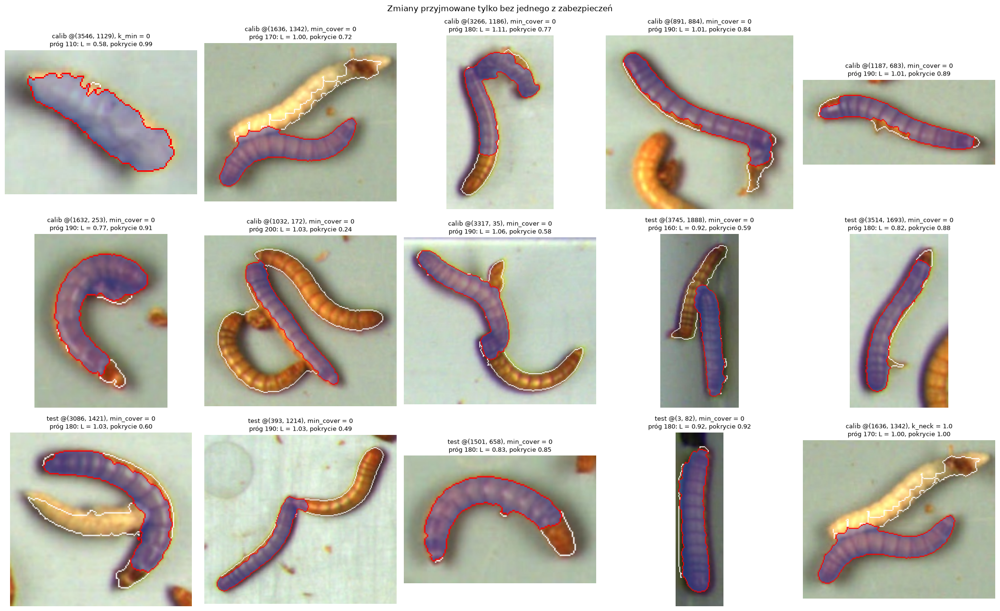

In [23]:
# Ablacja kroku 6: po jednym parametrze, reszta ma wartości końcowe. Krok 6 działa na gotowych kandydatach
# z kroku 5 (info['candidates']), więc segmentacji nie powtarzam.
variants = [('końcowe', {}), ('thr_step = 5', dict(thr_step=5)),
            ('open_k = 0', dict(open_k=0)), ('open_k = 3', dict(open_k=3)), ('open_k = 7', dict(open_k=7)),
            ('grow = 0', dict(grow=0)), ('grow = 3', dict(grow=3)), ('grow = 10', dict(grow=10)),
            ('min_part = 200', dict(min_part=200)), ('min_part = 1000', dict(min_part=1000)),
            ('k_min = 0', dict(k_min=0)), ('k_min = 0.6', dict(k_min=0.6)), ('k_min = 0.8', dict(k_min=0.8)),
            ('min_cover = 0', dict(min_cover=0)), ('min_cover = 0.9', dict(min_cover=0.9)),
            ('min_cover = 0.92', dict(min_cover=0.92)), ('min_cover = 0.96', dict(min_cover=0.96)),
            ('k_neck = 0', dict(k_neck=0)), ('k_neck = 0.3', dict(k_neck=0.3)), ('k_neck = 0.8', dict(k_neck=0.8)),
            ('k_neck = 1.0', dict(k_neck=1.0))]
GUARDS = ('k_min = 0', 'min_cover = 0', 'k_neck = 1.0')
final = {name: {s['cand']['bbox']: s['thr'] for s in info['splits']} for name, info in infos.items()}
table = ['| wariant | larwy `calib` | larwy `test` | zmiany dodane | zmiany utracone | ta sama zmiana, inny próg |',
         '|---|---|---|---|---|---|']
guard_cases = []
for label, kw in variants:
    larvae, added, lost, moved = [], 0, 0, 0
    for name, info in infos.items():
        splits = split_candidates(info['S'], info['candidates'], info['filt'], **kw)
        larvae.append(sum(c['reason'] is None for c in info['candidates']) + sum(len(s['parts']) for s in splits))
        thr = {s['cand']['bbox']: s['thr'] for s in splits}
        added += len(thr.keys() - final[name].keys())
        lost += len(final[name].keys() - thr.keys())
        moved += sum(thr[b] != final[name][b] for b in thr.keys() & final[name].keys())
        if label in GUARDS:
            guard_cases += [dict(s, img_name=name, label=label, L=[p['length_px'] / info['ref_len'] for p in s['parts']])
                            for s in splits if s['cand']['bbox'] not in final[name]]
    name_md = f'**{label}**' if label == 'końcowe' else f'`{label}`'
    table.append(f'| {name_md} | {larvae[0]} | {larvae[1]} | {added or ""} | {lost or ""} | {moved or ""} |')
display(Markdown('\n'.join(table)))
print('larwy przyjęte w kroku 5 krótsze niż k_min = 0.7 x mediana: ' + ', '.join(
    f"{name} {sum(c['length_px'] < 0.7 * info['ref_len'] for c in info['candidates'] if c['reason'] is None)}"
    f" z {sum(c['reason'] is None for c in info['candidates'])}" for name, info in infos.items()))

show_splits(images, guard_cases, cols=5, title='Zmiany przyjmowane tylko bez jednego z zabezpieczeń', accepted=False,
            title_fn=lambda s: (f"{s['img_name']} @{s['cand']['bbox'][:2]}, {s['label']}\n"
                                f"próg {s['thr']}: L = {', '.join(f'{l:.2f}' for l in s['L'])}, pokrycie {s['cover']:.2f}"))

**Uzasadnienie wartości końcowych:**

| parametr | końcowa | co się dzieje przy innych wartościach |
|---|---|---|
| `thr_step` | 10 | 5: te same zmiany (6 przy innym progu) i jedna więcej, blada larwa `test` @(632, 1251). Zysk jest pojedynczy, więc zostawiam 10. |
| `open_k` | 5 | 0 i 3: nie rozdziela pary `calib` @(2835, 1810) i nie oczyszcza `test` @(2238, 858), za to oczyszcza 2 inne larwy; przy 3 przechodzi też larwa na ściance `test` @(3, 82). 7: gubi parę `test` @(2770, 849) i larwy @(2238, 858), @(1797, 1123). |
| `grow` | 6 px | 0: części po wysokim progu są za cienkie, przepada 11 zmian. 3: przepadają 2 podziały zlepków, a zestaw oczyszczonych larw się zmienia (+5, −2); razem 1 larwa mniej. 10: szersza odbudowa dokleja wypustki z powrotem, przepada 7 zmian, dochodzą 2. |
| `min_part` | 500 px | 200: kawałek wylinki @(1797, 1123) staje się osobną częścią i podział przepada. 1000: ten sam zestaw zmian. |
| `k_min` | 0.7 | 0: przechodzi tylko oczyszczenie krótkiej bladej larwy `calib` @(3546, 1129) (0.58×). 0.6–0.8: ten sam wynik. |
| `min_cover` | 0.94 | 0: 13 dodatkowych zmian, prawie wszystkie złe (galeria). 0.9 i 0.92: ucięty ogon `calib` @(1632, 253) i larwa na ściance `test` @(3, 82). 0.93–0.96: ten sam zestaw zmian. Przyjęte zmiany mają pokrycie ≥ 0.95, a odrzucone ≤ 0.92. |
| `k_neck` | 0.5 | 0: wylinka liczy się do maski i przepada larwa `test` @(1797, 1123). 0.3–0.7: ten sam wynik. 0.8 i 1.0: przechodzi larwa z doklejonym kawałkiem bladej sąsiadki `calib` @(1636, 1342). |

**Wniosek (krok 6):**
* **Zlepki.** Spośród kandydatów odrzuconych w kroku 5 (27 na `calib`, 32 na `test`) krok 6 rozdziela na larwy 3 i 5 zlepków (+6 i +10 larw). Rozdzielają się pary, które stykają się końcami albo bokiem przez poświatę. Wśród nich jest para `test` @(707, 728), którą przy stałej `delta` = 30 rozcinała erozja w kroku 4 (kroki 3–4). Para `test` @(2438, 1700) już nie przechodzi: jedna z jej części ma wypustkę (nadmiar 15 px). Skrzyżowane larwy zostają odrzucone, bo przykryta larwa rozpada się na kawałki, które nie przechodzą `k_min` albo `min_cover`.
* **Wypustki.** Krok 6 usuwa wypustkę z 4 larw na `calib` i 5 na `test`, w tym z `test` @(3319, 2230) i @(1797, 1123), które przez okruch albo kawałek wylinki miały w kroku 5 duży nadmiar (39 i 168 px). Usunięte są okruchy i kawałki wylinki przyklejone do boku larwy oraz cienkie wyrostki na końcach. Reszta maski prawie się nie zmienia (pokrycie 0.95–1.00, galeria wyżej). Razem: `calib` 76 → 86 larw, `test` 82 → 97.
* **Dlaczego nie binaryzacja ani erozja B.** Piksele usunięte przez krok 6 mają średnio S = 154 i B = 53, a reszta maski tych larw S = 183 i B = 45. Wypustka jest więc trochę bledsza od ciała, ale dużo bardziej nasycona niż tło (próg lokalny ok. 100–115) i tak samo ciemna w B. Próg wspólny dla całego obrazu, który odciąłby wypustki, odciąłby wcześniej brzegi i blade fragmenty larw (sekcja o wrażliwości). Mocniejsza erozja B też nie pomaga: przy `alpha` = 0.15 nadmiar znika u 7 z 18 larw, ale u 7 innych rośnie (najbardziej 8 → 16 px i 4 → 13 px), blada larwa @(3546, 1129) odpada przez `grubosc`, a po stronie oświetlonej erozja wcina się w ciało wszystkich larw (kroki 3–4). Erozja działa na cały obrys, a wypustka to tylko jego mały fragment. Wyższy próg działa dopiero lokalnie, w obrębie jednej maski, czyli w kroku 6.
* **Wypustki, których krok 6 nie usuwa (6 na `calib`, 5 na `test`).** U 6 larw gałąź nie znika przy żadnym progu do 200: wyrostek jest tak samo nasycony jak ciało (np. ciemny wyrostek @(1863, 647)) albo larwa jest blada i jej maska ma wcięcia (@(3546, 1129), `test` @(632, 1251) i @(3158, 617)). U 5 gałąź znika dopiero przy progu 180–190, ale wtedy zostaje 84–91% maski: wysoki próg zjada brzeg albo koniec larwy (galeria niżej, `min_cover = 0`). Te larwy odpadają.
* **Otwarcie (`open_k` = 5).** Przy 0 i 3×3 na `calib` nie rozdziela się para @(2835, 1810), a na `test` zamiast wypustki @(2238, 858) znikają wypustki @(632, 1251) i @(1501, 658). Przy 3×3 przechodzi też larwa na ściance @(3, 82). Przy 7×7 na `test` giną para @(2770, 849) oraz larwy @(2238, 858) i @(1797, 1123), a dochodzą dwie inne zmiany (zlepek `calib` @(3098, 739) zamieniony na jedną larwę i wypustka `test` @(1645, 1954)). Każda wartość oczyszcza z wypustek trochę inny zestaw larw, ale przy 5 krok 6 rozdziela najwięcej zlepków. Wszystkie zmiany przy wartościach końcowych sprawdziłem wzrokowo.
* **Odbudowa (`grow` = 6 px).** Bez niej prawie nic nie przechodzi (`calib` 78 larw, `test` 91): części po wysokim progu są cieńsze i krótsze od larw. Przy 3 px znika po 1 podziale zlepka na każdym obrazie. Przy 10 px znika podział @(1759, 1867), a szersza odbudowa dokleja część wypustek z powrotem: znika 6 oczyszczeń (w tym larwy z okruchem @(3319, 2230) i z wylinką @(1797, 1123)), a dochodzą 2 inne.
* **`min_part`.** Przy 1000 px zestaw zmian jest ten sam. Przy 200 px kawałek wylinki @(1797, 1123) staje się osobną częścią, która nie przechodzi filtra, i ten podział przepada.
* **`k_min` = 0.7.** Bez niego przechodzi tylko oczyszczenie bladej larwy @(3546, 1129), która sama jest krótka (0.58×). Zły podział `test` @(393, 1214), który wcześniej łapał tylko `k_min` (kawałek larwy 0.49× razem z sąsiadką), odrzuca teraz także `min_cover`. Wśród larw przyjętych w kroku 5 krótsza niż 0.7× jest tylko jedna (skurczona larwa `calib`, 0.53×), więc ten próg rzadko szkodzi.
* **`min_cover` = 0.94** (wcześniej 0.9, gdy krok 6 dotyczył tylko zlepków). Bez niego przechodzi 13 dodatkowych zmian, prawie wszystkie złe: znika bledsza larwa, a jej koniec dokleja się do sąsiadki (np. `test` @(1028, 273), 0.71), jedna larwa przykrywa drugą (`calib` @(3005, 1813), 0.82) albo wysoki próg zjada koniec larwy (`calib` @(1632, 253): ogon ucięty, długość spada z 0.92× do 0.77× mediany, pokrycie 0.91). Przy 0.92 przechodzi larwa na ściance `test` @(3, 82) (0.92). Wszystkie przyjęte zmiany mają pokrycie ≥ 0.95, odrzucone ≤ 0.92, a zestaw zmian jest ten sam dla `min_cover` od 0.93 do 0.96. Kosztem jest zlepek `calib` @(1032, 172): obie części są dobre, ale znika trzecia larwa, która leży częściowo pod jedną z nich i styka się z nimi szeroko (pokrycie 0.50). Larwę `test` @(1797, 1123) z dużym kawałkiem wylinki ratuje `k_neck`: wylinka łączyła się z larwą szyjką szeroką na ok. 6 px, więc nie liczy się do maski (bez tego pokrycie wynosiłoby 0.82).
* **Krok progu 5** zamiast 10 daje te same podziały, część przy progu niższym o 5, i dodatkowo oczyszcza bladą larwę `test` @(632, 1251). Zysk to jedna larwa, więc zostawiam 10.
* Analiza instancji niżej korzysta z pełnego wyniku, czyli z kroków 1–6.

### Wynik: cały obraz kalibracyjny

Parametry końcowe na całym obrazie. Dochodzą trudniejsze przypadki: skrzyżowane i sklejone larwy, okruchy, odchody i larwy przy ściankach pudełka. Pod spodem jest po jednym przykładzie każdego wyniku (OK i każdy powód odrzucenia), krok po kroku.

calib: 86 larw (po kroku 5: 76), odrzucono: {'szkielet': 19, 'dlugosc': 1}, drobnych obiektów (< min_area): 289
mediana pola = 3218 px, mediana długości szkieletu = 156 px, mediana grubości = 21.6 px


<Axes: title={'center': '86 obiektów, 20 odrzuconych'}>

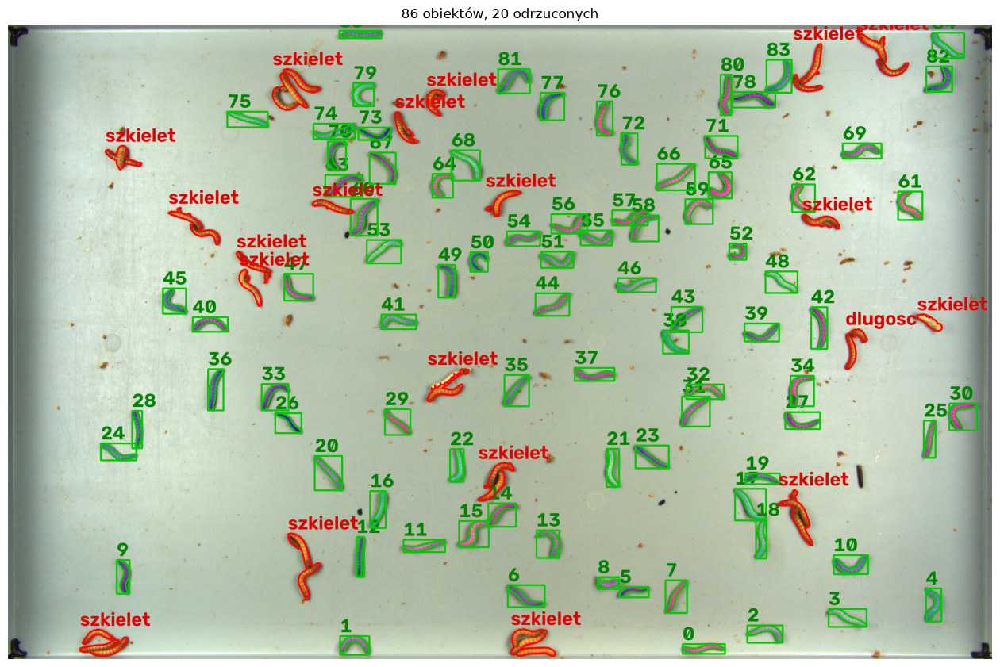

In [24]:
# Cały obraz kalibracyjny (kroki 1-6, detekcja policzona w sekcji kroku 5): zielone = przyjęte larwy, czerwone = odrzuceni kandydaci z powodem
print(f"calib: {len(objs_calib)} larw (po kroku 5: {sum(c['reason'] is None for c in dbg_calib['candidates'])}), odrzucono: {dict(Counter(c['reason'] for c in dbg_calib['rejected']))}, "
      f"drobnych obiektów (< min_area): {dbg_calib['n_small']}")
print(f"mediana pola = {dbg_calib['ref_area']:.0f} px, mediana długości szkieletu = {dbg_calib['ref_len']:.0f} px, "
      f"mediana grubości = {dbg_calib['ref_width']:.1f} px")
display_objects(calib, objs_calib, mode='both', rejected=dbg_calib['rejected'])

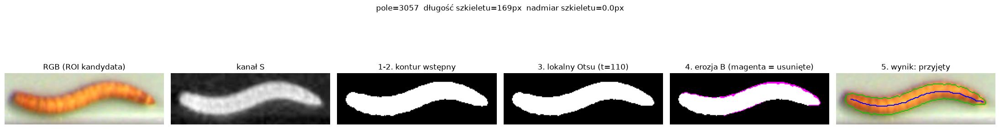

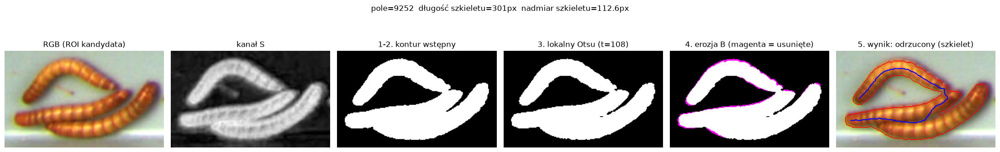

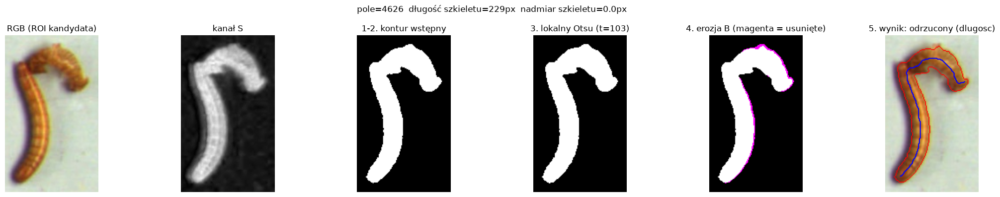

In [25]:
# Pojedyncze obiekty krok po kroku: po jednym przykładzie każdego wyniku (OK + każdy powód odrzucenia).
# Biorę kandydatów, których nie zmienił krok 6, więc decyzja w ostatnim panelu jest ostateczna.
changed = {id(s['cand']) for s in dbg_calib['splits']}
examples = {}
for c in dbg_calib['candidates']:
    if id(c) not in changed:
        examples.setdefault(c['reason'] or 'OK', c)
for reason, cand in examples.items():
    show_candidate_steps(calib, cand)

#### Dlaczego larwy zostały odrzucone

Wszystkie kandydaty z `calib` odrzucone ostatecznie (w kroku 5 i niepodzielone w kroku 6) w powiększeniu, z powodem i wartościami, które o nim zdecydowały. Odniesienia: nadmiar szkieletu < 30 px, długość < 1.35 × mediana, grubość < 1.25 × mediana.

mediany calib: długość 156 px, grubość 21.6 px, pole 3218 px


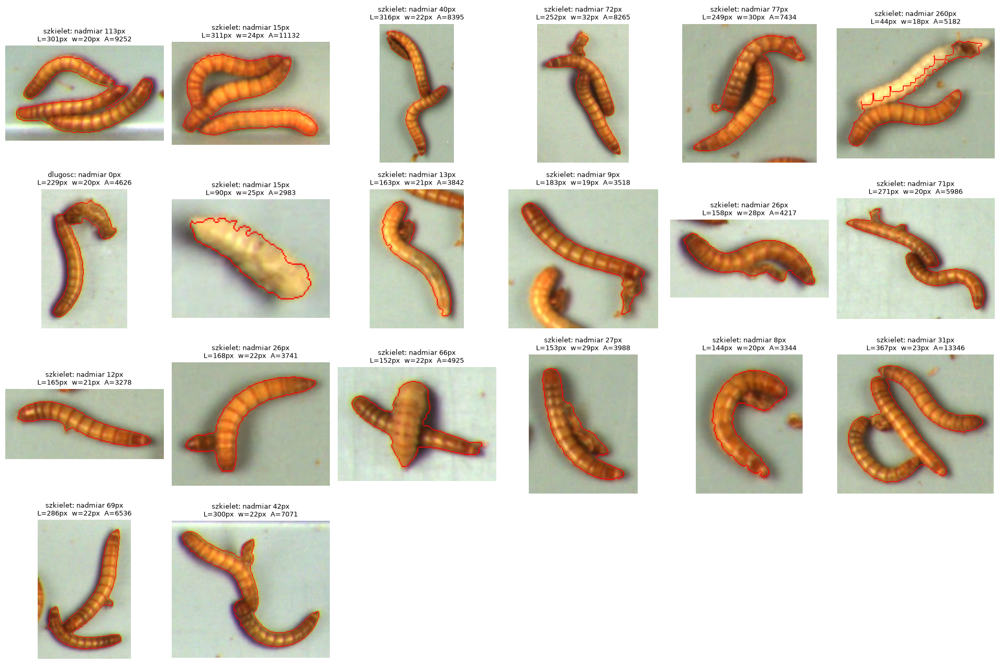

In [26]:
def rejection_title(c) -> str:
    return f"{c['reason']}: nadmiar {c['skeleton_extra']:.0f}px\nL={c['length_px']:.0f}px  w={c['width_est']:.0f}px  A={c['area']}"

print(f"mediany calib: długość {dbg_calib['ref_len']:.0f} px, grubość {dbg_calib['ref_width']:.1f} px, pole {dbg_calib['ref_area']:.0f} px")
show_gallery(calib, dbg_calib['rejected'], rejection_title)

#### Czego w ogóle nie wykrywamy

Odrzuceni kandydaci to nie wszystko. Część obiektów nie przechodzi już przez próg nasycenia (krok 1), więc w ogóle nie staje się kandydatem. Żeby je znaleźć, szukam obiektów wyraźnie innych od tła: ciemniejszych od lokalnej jasności tła albo choć trochę nasyconych, i niepokrytych przez żadnego kandydata. Przy każdym podaję średnie S, które trzeba porównać z progiem `S_THR` = 104.

calib: 9 obiektów spoza kandydatów


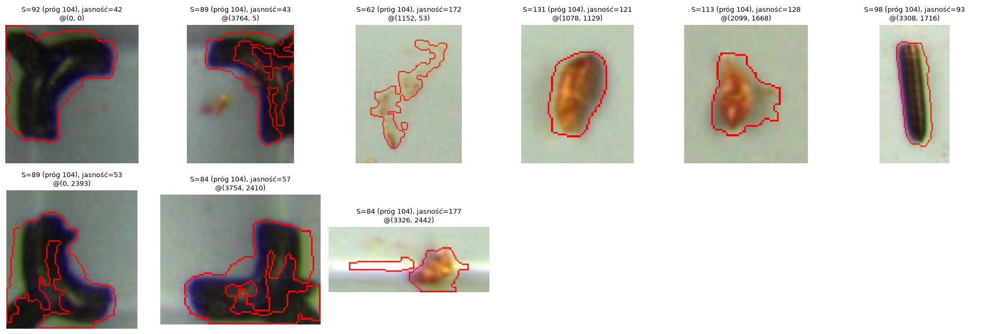

In [27]:
def find_missed(image: np.ndarray, info: dict, min_area: int = 1200, max_area: int = 20000):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    background = cv2.medianBlur(gray, 51)                       # lokalna jasność tła
    anything = ((np.abs(gray.astype(int) - background.astype(int)) > 35) | (hsv[..., 1] > 40)).astype(np.uint8)
    anything = cv2.morphologyEx(anything, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    covered = np.zeros_like(anything)
    for c in info['candidates']:
        cv2.drawContours(covered, [c['contour']], -1, 1, -1)
    covered = cv2.dilate(covered, np.ones((15, 15), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(anything)
    missed = []
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        if not (min_area <= a <= max_area):
            continue
        comp = (lab[y:y + h, x:x + w] == i)
        if covered[y:y + h, x:x + w][comp].mean() >= 0.2:
            continue
        cnts, _ = cv2.findContours(comp.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        missed.append(dict(bbox=(x, y, w, h), contour=max(cnts, key=cv2.contourArea) + [x, y], reason='brak',
                           mean_S=float(hsv[y:y + h, x:x + w, 1][comp].mean()),
                           mean_gray=float(gray[y:y + h, x:x + w][comp].mean())))
    return missed

missed_calib = find_missed(calib, dbg_calib)
print(f'calib: {len(missed_calib)} obiektów spoza kandydatów')
show_gallery(calib, missed_calib, lambda c: f"S={c['mean_S']:.0f} (próg {S_THR:.0f}), jasność={c['mean_gray']:.0f}\n@({c['bbox'][0]}, {c['bbox'][1]})")

### Wynik: obraz testowy

Te same parametry, bez zmian, na drugim obrazie. Progi względne liczone są na nowo z tego obrazu. Pod spodem: odrzuceni kandydaci i obiekty, których nie wykrywamy.

test: 97 larw (po kroku 5: 82), odrzucono: {'szkielet': 20, 'dlugosc': 1, 'grubosc': 1}, drobnych: 294
mediana pola: calib 3218 / test 3130,  mediana długości: calib 156 / test 153


<Axes: title={'center': '97 obiektów, 22 odrzuconych'}>

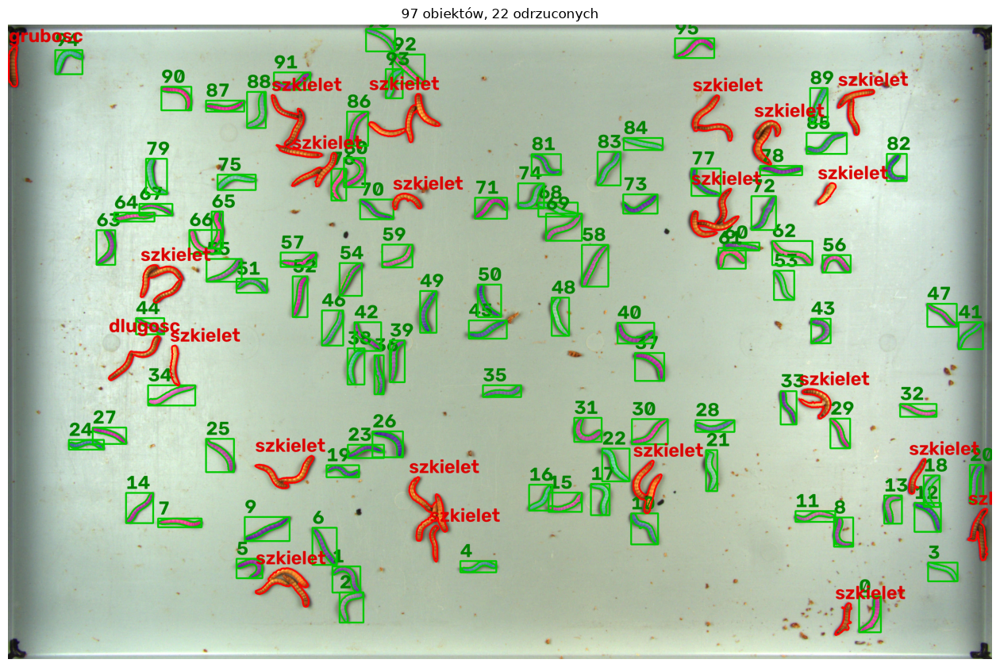

In [28]:
# Obraz testowy (kroki 1-6, detekcja policzona w sekcji kroku 5): te same parametry, także S_THR z calib; progi względne liczone na nowo z tego obrazu
print(f"test: {len(objs_test)} larw (po kroku 5: {sum(c['reason'] is None for c in dbg_test['candidates'])}), odrzucono: {dict(Counter(c['reason'] for c in dbg_test['rejected']))}, "
      f"drobnych: {dbg_test['n_small']}")
print(f"mediana pola: calib {dbg_calib['ref_area']:.0f} / test {dbg_test['ref_area']:.0f},  "
      f"mediana długości: calib {dbg_calib['ref_len']:.0f} / test {dbg_test['ref_len']:.0f}")
display_objects(test, objs_test, mode='both', rejected=dbg_test['rejected'])

test: 5 obiektów spoza kandydatów


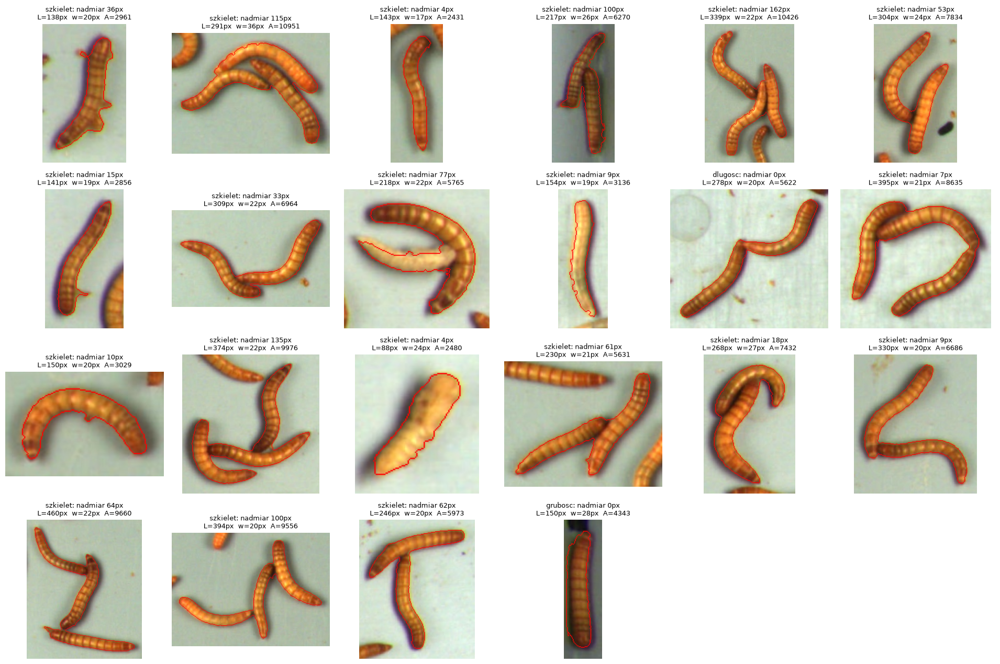

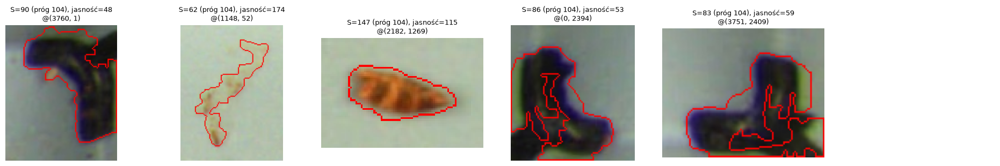

In [29]:
show_gallery(test, dbg_test['rejected'], rejection_title)
missed_test = find_missed(test, dbg_test)
print(f'test: {len(missed_test)} obiektów spoza kandydatów')
show_gallery(test, missed_test, lambda c: f"S={c['mean_S']:.0f} (próg {S_THR:.0f}), jasność={c['mean_gray']:.0f}\n@({c['bbox'][0]}, {c['bbox'][1]})")

#### Wyniki detekcji i dlaczego część larw się zgubiła

| | RoI | calib | test |
|---|---|---|---|
| larwy przyjęte w kroku 5 | 7 | 76 | 82 |
| krok 6: zlepki rozdzielone na larwy | – | 3 (+6) | 5 (+10) |
| krok 6: larwy oczyszczone z wypustki | – | 4 | 5 |
| **larwy w wyniku (kroki 1–6)** | **7** | **86** | **97** |
| odrzucone `szkielet` (skrzyżowane, zlepione, z wypustką) | 1 | 19 | 20 |
| odrzucone `dlugosc` (stykające się końcami) | – | 1 | 1 |
| odrzucone `grubosc` (larwa na ściance) | – | – | 1 |
| odrzucone `krawedz` (przecięte brzegiem RoI lub `FLOOR`) | 3 | – | – |
| drobne obiekty < 1500 px (okruchy, odchody) | – | 289 | 294 |

Mediany pola i długości są prawie takie same na obu obrazach (3218/3130 px, 156/153 px), więc parametry dobrane na `calib` przenoszą się na `test` bez zmian.

**Odrzuceni kandydaci** (galerie wyżej, już po kroku 6): prawie wszyscy to skrzyżowane, stykające się albo zlepione larwy, których krok 6 nie rozdzielił poprawnie, oraz larwy z wypustką, której krok 6 nie usunął. Wyjątki:
* na `test` larwa @(3226, 2256) z kilkoma przyklejonymi okruchami (nadmiar szkieletu 36 px). Krok 6 jej nie oczyszcza, więc zostaje odrzucona. To ostrożne, ale uzasadnione: do budowy bazy instancji lepiej zgubić larwę niż zapisać złą maskę. Podobną larwę z jednym okruchem, @(3319, 2230), krok 6 oczyszcza i przyjmuje;
* na `test` larwa wspinająca się po lewej ściance, odrzucona przez `grubosc`: jej maska obejmuje rozmyty cień na ściance, więc i tak byłaby za szeroka. Krok 6 przy progu 180 zdejmuje cień, ale zostaje 92% maski, mniej niż `min_cover`. Dzięki marginesowi 20 px wokół dna żaden obiekt na `calib` ani `test` nie dotyka brzegu obrazu, więc `krawedz` działa tylko na RoI.

**Obiekty, które w ogóle nie zostały kandydatami** (galerie „czego nie wykrywamy”):
* **narożniki dna pudełka:** czarne elementy w rogach prostokąta `FLOOR` (taśmy i pasków na krawędziach obrazu po przycięciu już nie ma). Pominięte słusznie: są ciemne, a ich fragmenty o S > 104 są mniejsze niż `min_area`;
* **ciemna larwa** (`calib`, ok. (3308, 1716) w układzie przyciętego obrazu): średnie S ≈ 98, czyli tuż pod progiem 104. To prawdziwa strata, bo ciemne, przepoczwarczające się osobniki mają mniej nasycony kolor;
* **krótkie pomarańczowe fragmenty:** S > 104, ale pole poniżej `min_area` = 1500 px. To fragmenty wylinek, główki albo zwinięte małe larwy. Obniżenie `min_area` wpuściłoby też grudki odchodów;
* **jasny, postrzępiony obiekt** o niskim S (≈ 62) przy górnej krawędzi dna, na obu zdjęciach w tym samym miejscu, prawdopodobnie fragment wylinki: słusznie pominięty.

**Inne ograniczenia:**
* jasne larwy (świeżo po wylince) mają niskie S i mogą zostać zgubione albo segmentowane tylko częściowo. Blada larwa `calib` @(3546, 1129) ma maskę z wcięciami w jasnych miejscach ciała i boczną gałąź szkieletu, więc odpada;
* larwy z wypustką, której krok 6 nie usuwa (6 na `calib`, 5 na `test`), odpadają. Wśród nich są maski naprawdę złe (@(901, 954) z kawałkiem ogona sąsiedniej larwy, @(1863, 647) z ciemnym wyrostkiem, @(891, 884) z paprochem na końcu), ale też larwy z drobnym guzkiem, np. odnóżem, których maska była poprawna. To koszt zasady, że maska nie może mieć wypustki.

### Analiza instancji: długość, kształt

`analyze_objects` przyjmuje listę instancji z `detect_objects` i dla każdej maski liczy:

**Długość** (miara główna, zwalidowana poniżej):
1. szkielet (`skeletonize`) wygładzonej maski i jego **najdłuższa ścieżka**, czyli oś larwy bez bocznych gałązek;
2. **wygładzenie osi** filtrem Gaussa. Szkielet to schodki w 8-sąsiedztwie, a ich długość jest większa niż długość gładkiej krzywej;
3. **przedłużenie obu końców** wzdłuż stycznej aż do brzegu maski. Szkielet kończy się mniej więcej jeden promień przed czubkiem larwy, więc bez tej korekty długość jest zaniżona. Brzeg wyznaczam podpikselowo (maska interpolowana dwuliniowo, brzeg na poziomie 0.5).

**Kształt I / C / S:** przebieg kąta stycznej wzdłuż osi, z pominięciem końcówek (po 10%, bo główka i ogon bywają lokalnie zagięte). Oś dzielę na zakręty, czyli odcinki o stałym znaku krzywizny, i liczę kąt skrętu każdego z nich:
* brak zakrętu ≥ 35° → **I**;
* co najmniej dwa znaczące zakręty w przeciwne strony → **S**;
* w przeciwnym razie → **C**.

Wszystkie wartości są w pikselach. Nie znamy skali obrazu (brak wzorca na zdjęciu), więc przeliczenie na mm wymagałoby kalibracji.

In [30]:
PAD = 2  # margines wokół maski, żeby brzeg obiektu nie leżał na brzegu tablicy


def polyline_length(p: np.ndarray) -> float:
    return float(np.linalg.norm(np.diff(p, axis=0), axis=1).sum()) if len(p) > 1 else 0.0


def resample_polyline(p: np.ndarray, step: float = 1.0) -> np.ndarray:
    """Równomierne próbkowanie łamanej co `step` px."""
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
    s = np.arange(0, d[-1], step)
    if d[-1] - s[-1] > 1e-6:
        s = np.r_[s, d[-1]]
    return np.c_[np.interp(s, d, p[:, 0]), np.interp(s, d, p[:, 1])]


def rays_to_edge(maskf: np.ndarray, points: np.ndarray, dirs: np.ndarray, step: float = 0.25, max_t: float = 60.0):
    """Dla każdego punktu: odległość wzdłuż zadanego kierunku do brzegu maski.
    Maska jest interpolowana dwuliniowo, a brzeg to poziom 0.5 (w połowie między pikselem obiektu i tła),
    więc wynik jest podpikselowy. Liczone wektorowo dla wszystkich punktów naraz."""
    dirs = dirs / (np.linalg.norm(dirs, axis=1, keepdims=True) + 1e-9)
    t = np.arange(step, max_t + step, step)
    q = points[:, None, :] + t[None, :, None] * dirs[:, None, :]
    vals = map_coordinates(maskf, q.reshape(-1, 2).T, order=1, mode='constant').reshape(len(points), len(t))
    outside = vals < 0.5
    first_out = np.where(outside.any(axis=1), outside.argmax(axis=1), len(t))
    return first_out * step


def classify_shape(centerline: np.ndarray, sigma: float = 6.0, trim: float = 0.1, lobe_deg: float = 35.0):
    """Klasyfikacja I / C / S na podstawie przebiegu kąta stycznej wzdłuż linii środkowej.
    Końcówki (`trim` długości z każdej strony) są pomijane, bo główka i ogon bywają lokalnie zagięte.
    Linię dzielę na zakręty (odcinki o stałym znaku krzywizny) i sumuję kąt skrętu w każdym:
      brak zakrętu >= lobe_deg -> I;  >= 2 znaczące zakręty o przeciwnych znakach -> S;  inaczej -> C."""
    p = np.c_[gaussian_filter1d(centerline[:, 0], sigma, mode='nearest'),
              gaussian_filter1d(centerline[:, 1], sigma, mode='nearest')]
    cut = int(trim * len(p))
    p = p[cut:len(p) - cut]
    if len(p) < 3:
        return 'I', dict(lobes=[], significant=[], theta=np.zeros(0))
    d = np.diff(p, axis=0)
    theta = np.unwrap(np.arctan2(d[:, 0], d[:, 1]))
    lobes, cur = [], 0.0
    for v in np.diff(theta):
        if cur == 0 or np.sign(v) == np.sign(cur):
            cur += v
        else:
            lobes.append(cur)
            cur = v
    lobes.append(cur)
    lobes = [float(np.degrees(l)) for l in lobes]
    significant = [l for l in lobes if abs(l) >= lobe_deg]
    if not significant:
        cls = 'I'
    elif any(np.sign(a) != np.sign(b) for a, b in zip(significant, significant[1:])):
        cls = 'S'
    else:
        cls = 'C'
    return cls, dict(lobes=lobes, significant=significant, theta=np.degrees(theta))


def analyze_instance(obj: dict, sigma: float = 3.0, k_dir: int = 8, open_k: int = 7, **shape_kw) -> dict:
    """Pomiar pojedynczej instancji na podstawie jej maski binarnej (obj['mask']).
      1. szkielet wygładzonej maski -> najdłuższa ścieżka (oś larwy, bez bocznych gałązek),
      2. wygładzenie osi filtrem Gaussa (usuwa schodki 8-sąsiedztwa, które zawyżają długość),
      3. przedłużenie obu końców wzdłuż stycznej aż do brzegu maski (szkielet kończy się ok. promień przed
         czubkiem larwy, co zaniża długość),
      4. kształt I/C/S z przebiegu kąta stycznej (classify_shape)."""
    m = np.pad(obj['mask'], PAD).astype(np.uint8)
    maskf = m.astype(np.float32)
    smooth_mask = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k)))
    skel = skm.skeletonize(smooth_mask > 0)
    geo_len, path = skeleton_longest_path(skel)
    res = dict(length_naive=float(skel.sum()), length_geodesic=float(geo_len))
    if len(path) < 2 * k_dir + 2:
        res.update(length=np.nan, length_smooth=np.nan, shape=None, straightness=np.nan)
        return res

    # 2. wygładzona oś, próbkowana co 1 px
    path = path.astype(np.float64)
    smooth = np.c_[gaussian_filter1d(path[:, 0], sigma, mode='nearest'),
                   gaussian_filter1d(path[:, 1], sigma, mode='nearest')]
    smooth = resample_polyline(smooth, 1.0)

    # 3. przedłużenie końców wzdłuż stycznej do brzegu maski
    k = min(k_dir, len(smooth) - 1)
    ends = np.array([smooth[0], smooth[-1]])
    dirs = np.array([smooth[0] - smooth[k], smooth[-1] - smooth[-1 - k]])
    dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
    ext = rays_to_edge(maskf, ends, dirs)
    tips = ends + ext[:, None] * dirs
    length_smooth = polyline_length(smooth)
    length = length_smooth + float(ext.sum())

    # 4. kształt
    shape, shape_info = classify_shape(smooth, **shape_kw)

    off = np.array([PAD, PAD])
    res.update(
        length=length,
        length_smooth=length_smooth,
        shape=shape,
        straightness=float(np.linalg.norm(tips[1] - tips[0]) / length),
        lobes=shape_info['significant'],
        centerline=np.vstack([tips[0], smooth, tips[1]]) - off,
        _debug=dict(skeleton=skel[PAD:-PAD, PAD:-PAD], path=path - off, smooth=smooth - off, tips=tips - off,
                    ext=ext, shape_info=shape_info),
    )
    return res


def analyze_objects(instances: List, **kwargs) -> List:
    """Analiza wszystkich instancji z detect_objects. Zwraca kopie słowników uzupełnione o:
    length [px], shape ('I'/'C'/'S'),
    straightness (cięciwa / długość), lobes (znaczące zakręty w stopniach), centerline (oś z końcami)."""
    return [{**obj, **analyze_instance(obj, **kwargs)} for obj in instances]

In [31]:
def show_analysis(a: dict, image: np.ndarray = None):
    """Podgląd analizy krok po kroku dla jednej instancji (wynik analyze_objects / analyze_instance)."""
    d, mask = a['_debug'], a['mask']
    n = 4 if image is not None else 3
    f, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.5))
    if image is not None:
        x, y, w, h = a['bbox']
        axes[0].imshow(image[y:y + h, x:x + w, ::-1])
        axes[0].set_title('RGB')
        axes[0].axis('off')
    a1, a2, a3 = axes[-3:]

    a1.imshow(mask, cmap='gray')
    sy, sx = np.nonzero(d['skeleton'])
    a1.plot(sx, sy, 'c.', ms=2, label='szkielet')
    a1.plot(d['path'][:, 1], d['path'][:, 0], 'r-', lw=1, label='najdłuższa ścieżka')
    a1.legend(fontsize=7, loc='lower right')
    a1.set_title(f"1. szkielet {a['length_naive']:.0f} px, ścieżka {a['length_geodesic']:.0f} px", fontsize=9)

    a2.imshow(mask, cmap='gray')
    a2.plot(d['smooth'][:, 1], d['smooth'][:, 0], 'r-', lw=1.5)
    for tip, end in zip(d['tips'], d['smooth'][[0, -1]]):
        a2.plot([end[1], tip[1]], [end[0], tip[0]], 'y-', lw=2.5)
    a2.plot(d['tips'][:, 1], d['tips'][:, 0], 'yo', ms=4)
    a2.set_title(f"2. wygładzona + końce (żółte): L = {a['length']:.1f} px", fontsize=9)

    for ax in (a1, a2):
        ax.axis('off')

    si = d['shape_info']
    if len(si['theta']):
        a3.plot(si['theta'] - si['theta'][0], 'b-')
    a3.axhline(0, color='gray', lw=0.5)
    a3.set_xlabel('px wzdłuż linii (bez końcówek)')
    a3.set_ylabel('kąt stycznej względem początku [°]')
    a3.set_title(f"3. kształt {a['shape']}: zakręty {[round(l) for l in si['significant']]}°", fontsize=9)
    plt.tight_layout()

kształty  calib: {'S': 10, 'C': 63, 'I': 13}   test: {'C': 66, 'S': 9, 'I': 22}


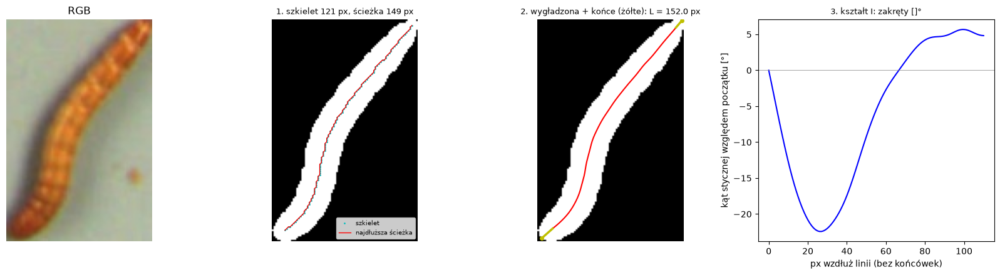

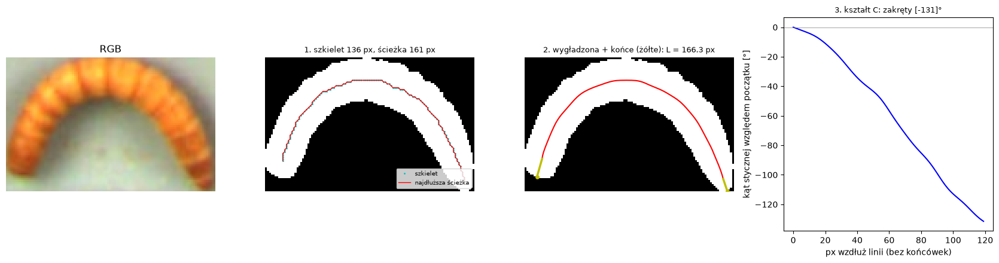

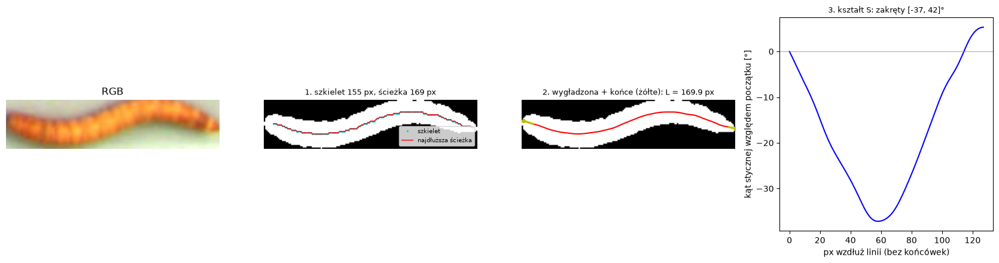

In [32]:
an_calib = analyze_objects(objs_calib)
an_test = analyze_objects(objs_test)
print('kształty  calib:', dict(Counter(a['shape'] for a in an_calib)), '  test:', dict(Counter(a['shape'] for a in an_test)))

# Analiza krok po kroku: po jednym przykładzie każdej klasy kształtu
for cls in 'ICS':
    show_analysis(next(a for a in an_calib if a['shape'] == cls), calib)

#### Długość w klasach kształtu: statystyki i przykłady

Dla każdej klasy kształtu, osobno na `calib` i `test`, pokazuję:
* **tabelę** statystyk długości: min, kwartyle, mediana, max, średnia i odchylenie standardowe;
* **wykres pudełkowy** tych samych liczb: pudełko to Q1–Q3, kreska w środku to mediana, wąsy sięgają min i max, punkty to pojedyncze larwy;
* **galerię po 5 larw na klasę**: z klasy posortowanej według długości biorę larwy z pozycji min, Q1, mediany, Q3 i max. Galeria jest więc podglądem liczb z tabeli, a skrajne długości to miejsca, gdzie najłatwiej o błąd maski.

Każdą larwę pokazuję dwa razy: na RGB z zielonym konturem maski i na samej masce. Na obu panelach jest linia środkowa (niebieska), wzdłuż której liczę długość, z końcami (żółte). Wszystkie wycinki mają ten sam rozmiar, więc długości można porównywać na oko.

**Długość [px] w klasach kształtu**

| obraz | kształt | n | min | Q1 | mediana | Q3 | max | średnia | odch. std |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| calib | I | 13 | 133.3 | 152.0 | 156.4 | 165.5 | 177.2 | 157.1 | 10.5 |
| calib | C | 63 | 97.5 | 152.3 | 161.5 | 167.2 | 181.9 | 158.3 | 14.7 |
| calib | S | 10 | 149.7 | 154.4 | 163.5 | 169.1 | 179.7 | 162.7 | 9.1 |
| calib | wszystkie | 86 | 97.5 | 152.1 | 161.4 | 167.1 | 181.9 | 158.6 | 13.7 |
| test | I | 22 | 123.5 | 151.3 | 157.7 | 167.1 | 195.8 | 159.2 | 17.8 |
| test | C | 66 | 132.3 | 150.4 | 159.6 | 165.0 | 184.0 | 158.2 | 11.6 |
| test | S | 9 | 141.3 | 149.4 | 163.9 | 170.2 | 186.6 | 162.7 | 14.4 |
| test | wszystkie | 97 | 123.5 | 150.3 | 159.6 | 166.7 | 195.8 | 158.9 | 13.6 |

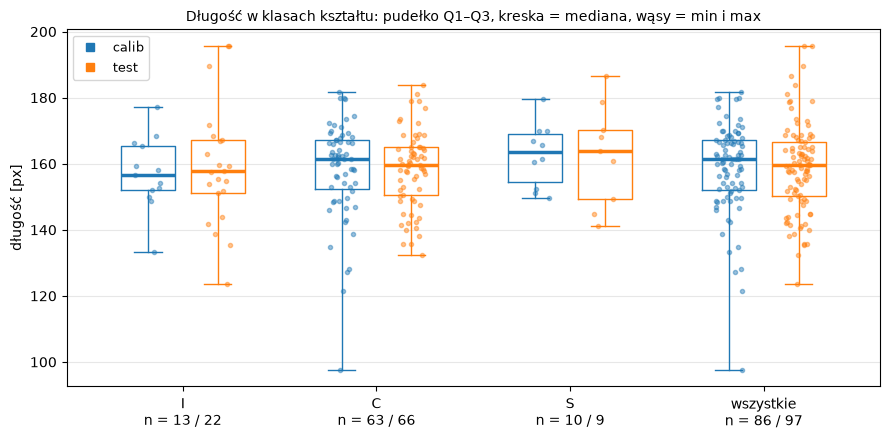

In [33]:
# Długość w klasach kształtu: tabela statystyk i wykres pudełkowy (wąsy = min i max, punkty = pojedyncze larwy)
analyses = {'calib': an_calib, 'test': an_test}
SHAPES = ['I', 'C', 'S', 'wszystkie']
STATS = [('min', np.min), ('Q1', lambda v: np.percentile(v, 25)), ('mediana', np.median),
         ('Q3', lambda v: np.percentile(v, 75)), ('max', np.max), ('średnia', np.mean), ('odch. std', np.std)]


def lengths_by_shape(an: List, cls: str) -> np.ndarray:
    return np.array([a['length'] for a in an if cls == 'wszystkie' or a['shape'] == cls])


table = ['| obraz | kształt | n | ' + ' | '.join(s for s, _ in STATS) + ' |', '|---|---|---:' + '|---:' * len(STATS) + '|']
for name, an in analyses.items():
    for cls in SHAPES:
        v = lengths_by_shape(an, cls)
        table.append(f'| {name} | {cls} | {len(v)} | ' + ' | '.join(f'{fn(v):.1f}' for _, fn in STATS) + ' |')
display(Markdown('**Długość [px] w klasach kształtu**\n\n' + '\n'.join(table)))

f, ax = plt.subplots(figsize=(9, 4.5))
jitter = np.random.default_rng(0)
for j, (name, an) in enumerate(analyses.items()):
    color = f'C{j}'  # te same kolory calib / test co na histogramie niżej
    for k, cls in enumerate(SHAPES):
        v = lengths_by_shape(an, cls)
        pos = k + (j - 0.5) * 0.36
        ax.boxplot(v, positions=[pos], widths=0.28, whis=(0, 100), showfliers=False,
                   boxprops=dict(color=color), whiskerprops=dict(color=color), capprops=dict(color=color),
                   medianprops=dict(color=color, lw=2.5))
        ax.plot(pos + jitter.uniform(-0.07, 0.07, len(v)), v, 'o', color=color, ms=3, alpha=0.45)
    ax.plot([], [], 's', color=color, label=name)
ax.set_xticks(range(len(SHAPES)),
              [f'{cls}\nn = {len(lengths_by_shape(an_calib, cls))} / {len(lengths_by_shape(an_test, cls))}' for cls in SHAPES])
ax.set_xlim(-0.6, len(SHAPES) - 0.4)
ax.set_ylabel('długość [px]')
ax.set_title('Długość w klasach kształtu: pudełko Q1–Q3, kreska = mediana, wąsy = min i max', fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()

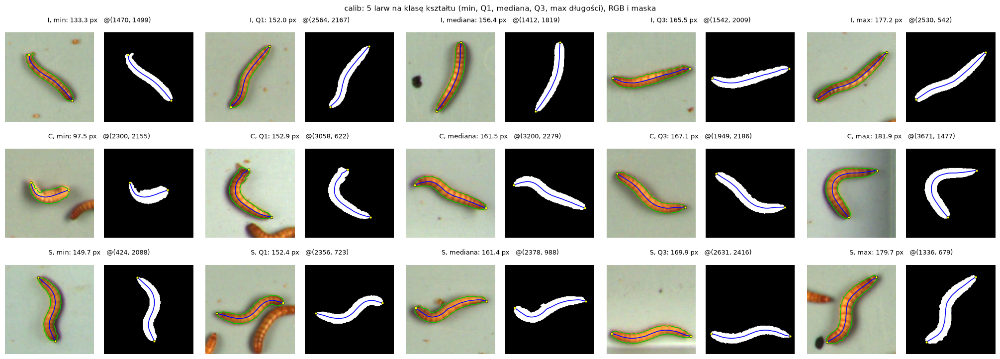

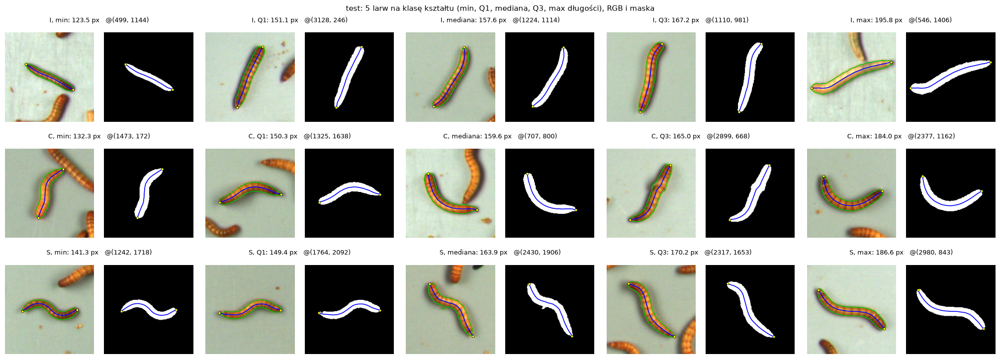

In [34]:
# Galeria po 5 larw na klasę kształtu (min, Q1, mediana, Q3, max długości), na RGB i na masce, dla calib i test
LENGTH_QS = [('min', 0), ('Q1', 25), ('mediana', 50), ('Q3', 75), ('max', 100)]


def length_examples(an: List, cls: str) -> List:
    """5 larw klasy `cls`: po posortowaniu według długości larwy z pozycji q·(n-1) dla q = 0, 25, 50, 75, 100%."""
    group = sorted((a for a in an if a['shape'] == cls), key=lambda a: a['length'])
    return [(label, group[round(q / 100 * (len(group) - 1))]) for label, q in LENGTH_QS]


def show_length_examples(image: np.ndarray, an: List, title: str = None, pad: int = 10):
    """Wiersz = klasa kształtu, w nim 5 larw (length_examples), każda w osobnej podfigurze z dwoma panelami:
    RGB z zielonym konturem maski i sama maska. Na obu linia środkowa (niebieska) i jej końce (żółte). Wycinki są kwadratami tego samego
    rozmiaru (najdłuższy bok bbox w galerii + 2·pad), więc skala jest wspólna dla całej galerii."""
    examples = {cls: length_examples(an, cls) for cls in 'ICS'}
    side = max(max(a['bbox'][2:]) for ex in examples.values() for _, a in ex) + 2 * pad
    H, W = image.shape[:2]
    f = plt.figure(figsize=(4 * len(LENGTH_QS), 2.4 * len(examples)), layout='constrained')
    subfigs = f.subfigures(len(examples), len(LENGTH_QS), wspace=0.04)
    for r, (cls, ex) in enumerate(examples.items()):
        for k, (label, a) in enumerate(ex):
            x, y, w, h = a['bbox']
            x0 = int(np.clip(x + w // 2 - side // 2, 0, W - side))
            y0 = int(np.clip(y + h // 2 - side // 2, 0, H - side))
            mask = np.zeros((side, side), np.uint8)
            mask[y - y0:y - y0 + h, x - x0:x - x0 + w] = a['mask']
            cnt = a['contour'][:, 0] - [x0, y0]
            cl = a['centerline'] + [y - y0, x - x0]  # (wiersz, kolumna) w układzie wycinka
            sf = subfigs[r, k]
            ax_rgb, ax_mask = sf.subplots(1, 2)
            ax_rgb.imshow(image[y0:y0 + side, x0:x0 + side, ::-1])
            ax_rgb.plot(*np.r_[cnt, cnt[:1]].T, '-', color=np.array(ACCEPT_RGB) / 255, lw=1)
            ax_mask.imshow(mask, cmap='gray')
            for ax in (ax_rgb, ax_mask):
                ax.plot(cl[:, 1], cl[:, 0], '-', color='blue', lw=1.2)
                ax.plot(cl[[0, -1], 1], cl[[0, -1], 0], 'o', color='yellow', ms=3.5, mec='black', mew=0.5)
                ax.axis('off')
            sf.suptitle(f'{cls}, {label}: {a["length"]:.1f} px   @({x}, {y})', fontsize=9)
    if title:
        f.suptitle(title, fontsize=11)


for name, image, an in (('calib', calib, an_calib), ('test', test, an_test)):
    show_length_examples(image, an, f'{name}: 5 larw na klasę kształtu (min, Q1, mediana, Q3, max długości), RGB i maska')

#### Walidacja pomiaru na syntetycznych larwach

Do prawdziwych larw nie ma pomiaru referencyjnego, więc dokładność sprawdzam na **syntetycznych maskach o znanej długości i kształcie**. Generuję 60 larw: po 20 kształtów I, C i S, z losową długością 120–200 px, grubością 17–24 px, obrotem i zwężonymi końcami (jak u prawdziwych larw). Porównuję kolejne warianty metody, żeby pokazać, co daje każdy krok.

DŁUGOŚĆ                         błąd śr.  odch. std  |błąd| wzgl.
liczba pikseli szkieletu         -24.12px     8.60px       14.80 %
najdłuższa ścieżka szkieletu      -3.55px     3.75px        2.77 %
wygładzona linia środkowa        -15.12px     2.68px        9.39 %
wygładzona + przedłużone końce    -1.04px     1.09px        0.77 %

KSZTAŁT (prawdziwy -> przewidziany): {('I', 'I'): 20, ('C', 'C'): 20, ('S', 'S'): 20}


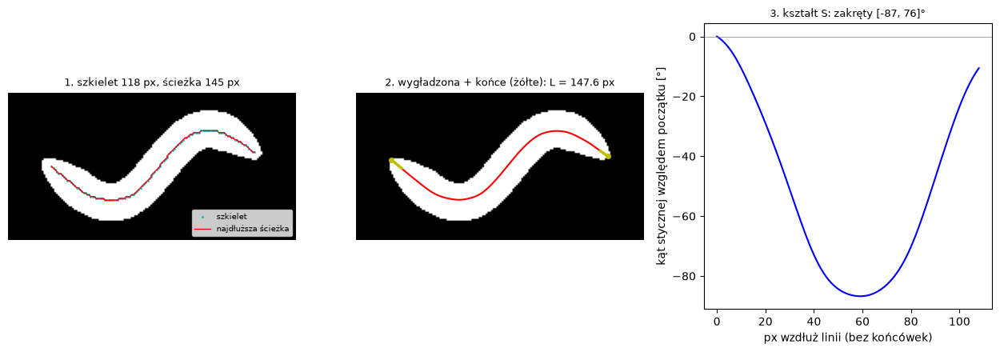

In [35]:
def make_synthetic_larva(kind: str, length: float, width: float, angle: float, taper: float = 0.15, r_min: float = 1.0):
    """Syntetyczna maska larwy o znanej linii środkowej: I (prosta), C (łuk 180°), S (sinusoida).
    Promień zwęża się na końcach (`taper` = część długości). Zwraca (maska, długość GT).
    GT liczę w zasięgu pikseli: cv2.circle zapala piksele o środku w odległości <= r, więc brzeg maski
    leży 0.5 px dalej, czyli figura jest o 1 px dłuższa niż wynika z parametrów (sprawdzone)."""
    s = np.linspace(0, length, int(length * 4))
    if kind == 'I':
        x, y = s, np.zeros_like(s)
    elif kind == 'C':
        R = length / np.pi
        x, y = R * np.sin(s / R), R * (1 - np.cos(s / R))
    else:  # S: sinusoida sparametryzowana długością łuku
        xx = np.linspace(0, length, 20000)
        yy = 0.12 * length * np.sin(2 * np.pi * xx / (0.75 * length))
        arc = np.r_[0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        x, y = np.interp(s, arc, xx), np.interp(s, arc, yy)
    c, sn = np.cos(angle), np.sin(angle)
    X, Y = c * x - sn * y, sn * x + c * y
    X, Y = X - X.min() + width, Y - Y.min() + width
    mask = np.zeros((int(Y.max() + width) + 2, int(X.max() + width) + 2), np.uint8)
    u = s / length
    r = np.maximum(width / 2 * np.clip(np.minimum(u, 1 - u) / taper, 0, 1) ** 0.5, r_min)
    for xi, yi, ri in zip(X, Y, r):
        cv2.circle(mask, (int(round(xi * 8)), int(round(yi * 8))), int(round(ri * 8)), 1, -1, shift=3)
    return mask, length + 2 * r_min + 1


rng = np.random.default_rng(0)
synth = []
for kind in 'ICS':
    for _ in range(20):
        L, W = rng.uniform(120, 200), rng.uniform(17, 24)
        mask, gt_len = make_synthetic_larva(kind, L, W, rng.uniform(0, np.pi))
        synth.append(dict(kind=kind, gt_len=gt_len, mask=mask, **analyze_instance({'mask': mask})))

gt_len = np.array([r['gt_len'] for r in synth])
print(f"{'DŁUGOŚĆ':30s} {'błąd śr.':>9s} {'odch. std':>10s} {'|błąd| wzgl.':>13s}")
for key, name in [('length_naive', 'liczba pikseli szkieletu'), ('length_geodesic', 'najdłuższa ścieżka szkieletu'),
                  ('length_smooth', 'wygładzona linia środkowa'), ('length', 'wygładzona + przedłużone końce')]:
    err = np.array([r[key] for r in synth]) - gt_len
    print(f'{name:30s} {err.mean():+8.2f}px {err.std():8.2f}px {100 * np.mean(np.abs(err) / gt_len):11.2f} %')
print('\nKSZTAŁT (prawdziwy -> przewidziany):', dict(Counter((r['kind'], r['shape']) for r in synth)))

# podgląd jednego syntetycznego przykładu S
show_analysis(next(r for r in synth if r['kind'] == 'S'))

I: n= 35, mediana długości  157.6 px, IQR 151-167
C: n=129, mediana długości  160.1 px, IQR 151-166
S: n= 19, mediana długości  163.9 px, IQR 152-170


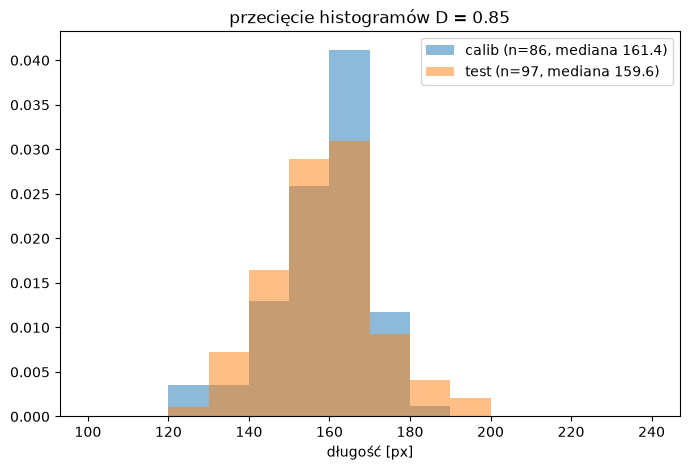

In [36]:
# Statystyki populacji: calib vs test.
# Zdjęcia zrobiono w odstępie ~1 min, więc to najpewniej te same larwy w innych pozach (jak seria zdjęć
# w artykule). Rozkłady powinny się więc pokrywać - to test powtarzalności pomiaru niezależnie od pozy.
# Miara zgodności: przecięcie histogramów D = sum(min(h1, h2)) - ta sama, której używa artykuł (wzór 2).
def hist_intersection(a, b, bins) -> float:
    ha, _ = np.histogram(a, bins)
    hb, _ = np.histogram(b, bins)
    return float(np.minimum(ha / ha.sum(), hb / hb.sum()).sum())

bins = np.arange(100, 241, 10)
vc, vt = [a['length'] for a in an_calib], [a['length'] for a in an_test]
f, ax = plt.subplots(figsize=(8, 5))
ax.hist(vc, bins, alpha=0.5, density=True, label=f'calib (n={len(vc)}, mediana {np.median(vc):.1f})')
ax.hist(vt, bins, alpha=0.5, density=True, label=f'test (n={len(vt)}, mediana {np.median(vt):.1f})')
ax.set_xlabel('długość [px]')
ax.set_title(f'przecięcie histogramów D = {hist_intersection(vc, vt, bins):.2f}')
ax.legend()

# Czy długość zależy od pozy? Jeśli pomiar jest dobry, mediany w klasach I/C/S powinny być zbliżone.
for cls in 'ICS':
    v = [a['length'] for a in an_calib + an_test if a['shape'] == cls]
    print(f'{cls}: n={len(v):3d}, mediana długości {np.median(v):6.1f} px, IQR {np.percentile(v, 25):.0f}-{np.percentile(v, 75):.0f}')

#### Wnioski z analizy

**Długość (miara główna).** Walidacja na 60 syntetycznych larwach:

| metoda | błąd średni | odch. std | średni \|błąd\| względny |
|---|---|---|---|
| liczba pikseli szkieletu (naiwnie) | −24.1 px | 8.6 px | 14.8 % |
| najdłuższa ścieżka szkieletu | −3.6 px | 3.8 px | 2.8 % |
| wygładzona linia środkowa | −15.1 px | 2.7 px | 9.4 % |
| **wygładzona + przedłużone końce** | **−1.0 px** | **1.1 px** | **0.8 %** |

* Naiwne liczenie pikseli szkieletu zaniża długość o ok. 15%, bo krok ukośny liczy się jako 1 zamiast √2, a szkielet kończy się przed czubkami.
* Najdłuższa ścieżka daje mały błąd średni, ale tylko dzięki temu, że dwa błędy się znoszą: schodki zawyżają długość, a skrócone końce ją zaniżają. Rozrzut pozostaje duży (σ = 3.8 px).
* Samo wygładzenie usuwa schodki i odsłania prawdziwy niedomiar na końcach (≈ −15 px, czyli ok. jeden promień z każdej strony).
* Przedłużenie końców ten niedomiar usuwa. Zostaje ok. −1 px, bo przy zwężonym czubku promień trafia w brzeg odrobinę wcześniej.

Każdy krok ma więc uzasadnienie, a końcowa metoda jest prawie nieobciążona i ma rozrzut ok. 1 px.

**Kształt.** Na syntetykach 60/60 trafień. Na prawdziwych larwach przeważają C (≈ 2/3), potem I i S. Granica między łagodnym C a I oraz między C a S zależy od progu `lobe_deg`. Nie ma tu „prawdziwej” etykiety, więc warto ocenić galerię wzrokowo.

**Powtarzalność na prawdziwych danych.** Dwa zdjęcia zrobione w odstępie ok. 1 min dają zgodne rozkłady długości: przecięcie histogramów D ≈ 0.85, mediany 161.4 i 159.6 px. Bez kroku 6 zgodność wynosiła 0.81. Mediana długości jest podobna dla larw I, C i S (≈ 158–164 px). To sugeruje, że pomiar nie zależy mocno od pozy: wygięta larwa nie wychodzi krótsza.

**Ograniczenia:**
* Pomiar jest dokładny względem **maski**, więc błędy segmentacji (brzeg zależny od erozji na kanale B, okruchy na przedłużeniu osi, które nie tworzą bocznej gałęzi szkieletu) przechodzą wprost na długość.
* Mocno zwinięte larwy (prawie pierścień, końce blisko siebie) mają niepewne końce szkieletu.
* Najkrótsza larwa (ok. 97 px, poza zakresem histogramu) to skurczona larwa `calib` @(2300, 2155). Blada larwa @(3546, 1129), wcześniej odstająca, odpada teraz przez boczną gałąź szkieletu.
* Brak skali, więc wyniki są w pikselach.